# Deep Neural Networks - Programming Assignment
## RNN, LSTM, GRU and Transformer

**Student Name:** __Sithara N T__  
**Student ID:** __2026AJ05271__

In [1]:
import sys
import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
import os

print("Python:", sys.version)
print("PyTorch:", torch.__version__)
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("Scikit-learn:", sklearn.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

Python: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
PyTorch: 2.14.1+cu130
NumPy: 2.4.6
Pandas: 2.2.3
Scikit-learn: 1.6.1
CUDA available: True
GPU: Tesla T4


In [2]:
import urllib.request
import zipfile

# Create project folders
folders = ["data", "notebooks", "results", "models", "plots"]

for folder in folders:
    os.makedirs(folder, exist_ok=True)

# Download UCI HAR dataset
url = "https://archive.ics.uci.edu/static/public/240/human+activity+recognition+using+smartphones.zip"

outer_zip = "data/UCI_HAR_Dataset.zip"

urllib.request.urlretrieve(url, outer_zip)

# Extract outer ZIP
with zipfile.ZipFile(outer_zip, "r") as zip_ref:
    zip_ref.extractall("data/")

# Extract inner ZIP
inner_zip = "data/UCI HAR Dataset.zip"

with zipfile.ZipFile(inner_zip, "r") as zip_ref:
    zip_ref.extractall("data/")

# Verify dataset
dataset_path = "data/UCI HAR Dataset"

print("Dataset downloaded and extracted successfully!")
print("Dataset folders:", os.listdir(dataset_path))
print("Training files:", os.listdir(os.path.join(dataset_path, "train")))
print("Testing files:", os.listdir(os.path.join(dataset_path, "test")))

Dataset downloaded and extracted successfully!
Dataset folders: ['test', 'train', 'README.txt', 'activity_labels.txt', 'features_info.txt', 'features.txt', '.DS_Store']
Training files: ['Inertial Signals', 'X_train.txt', 'y_train.txt', 'subject_train.txt']
Testing files: ['y_test.txt', 'Inertial Signals', 'X_test.txt', 'subject_test.txt']


In [3]:

dataset_path = "data/UCI HAR Dataset"

# Load training data
X_train = np.loadtxt(os.path.join(dataset_path, "train", "X_train.txt"))
y_train = np.loadtxt(os.path.join(dataset_path, "train", "y_train.txt")).astype(int)
subject_train = np.loadtxt(os.path.join(dataset_path, "train", "subject_train.txt")).astype(int)

# Load testing data
X_test = np.loadtxt(os.path.join(dataset_path, "test", "X_test.txt"))
y_test = np.loadtxt(os.path.join(dataset_path, "test", "y_test.txt")).astype(int)
subject_test = np.loadtxt(os.path.join(dataset_path, "test", "subject_test.txt")).astype(int)

print("Training data shape:", X_train.shape)
print("Training labels shape:", y_train.shape)
print("Testing data shape:", X_test.shape)
print("Testing labels shape:", y_test.shape)
print("Number of training subjects:", len(np.unique(subject_train)))
print("Number of testing subjects:", len(np.unique(subject_test)))

Training data shape: (7352, 561)
Training labels shape: (7352,)
Testing data shape: (2947, 561)
Testing labels shape: (2947,)
Number of training subjects: 21
Number of testing subjects: 9


Training activity distribution:
Laying                1407
Standing              1374
Sitting               1286
Walking               1226
Walking Upstairs      1073
Walking Downstairs     986
Name: count, dtype: int64


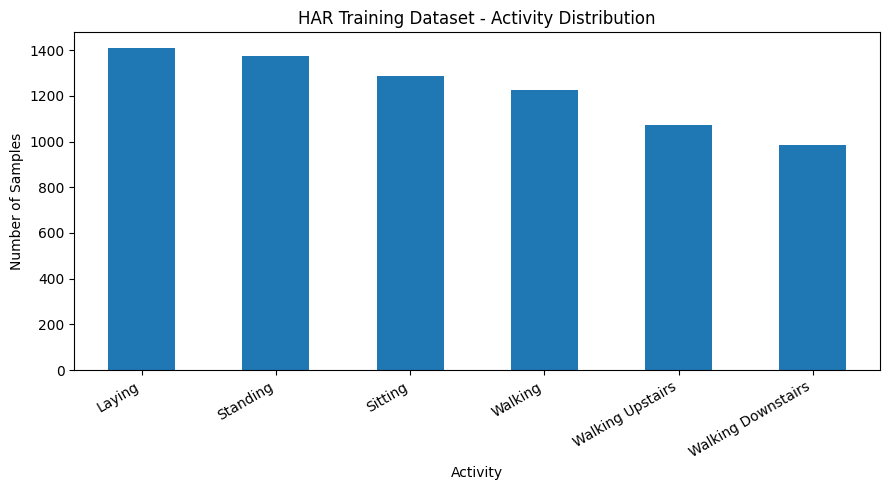

In [4]:

activity_labels = {
    1: "Walking",
    2: "Walking Upstairs",
    3: "Walking Downstairs",
    4: "Sitting",
    5: "Standing",
    6: "Laying"
}

train_distribution = pd.Series(y_train).map(activity_labels).value_counts()

print("Training activity distribution:")
print(train_distribution)

plt.figure(figsize=(9, 5))
train_distribution.plot(kind="bar")
plt.title("HAR Training Dataset - Activity Distribution")
plt.xlabel("Activity")
plt.ylabel("Number of Samples")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()


In [5]:
from sklearn.model_selection import GroupShuffleSplit

splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

train_idx, val_idx = next(
    splitter.split(X_train, y_train, groups=subject_train)
)

X_train_split = X_train[train_idx]
y_train_split = y_train[train_idx]

X_val = X_train[val_idx]
y_val = y_train[val_idx]

subject_train_split = subject_train[train_idx]
subject_val = subject_train[val_idx]

print("Training samples:", X_train_split.shape)
print("Validation samples:", X_val.shape)

print("Training subjects:", np.unique(subject_train_split))
print("Validation subjects:", np.unique(subject_val))

print(
    "Subject overlap:",
    set(subject_train_split).intersection(set(subject_val))
)

Training samples: (5551, 561)
Validation samples: (1801, 561)
Training subjects: [ 5  6  7  8 11 14 16 17 19 21 22 23 26 28 29 30]
Validation subjects: [ 1  3 15 25 27]
Subject overlap: set()


In [6]:

signal_path = os.path.join(
    "data", "UCI HAR Dataset", "train", "Inertial Signals"
)

print(os.listdir(signal_path))

['total_acc_y_train.txt', 'body_gyro_x_train.txt', 'total_acc_z_train.txt', 'body_acc_y_train.txt', 'body_acc_x_train.txt', 'total_acc_x_train.txt', 'body_gyro_y_train.txt', 'body_gyro_z_train.txt', 'body_acc_z_train.txt']


In [7]:
train_signal_path = "data/UCI HAR Dataset/train/Inertial Signals"

signal_names = [
    "total_acc_x",
    "total_acc_y",
    "total_acc_z",
    "body_acc_x",
    "body_acc_y",
    "body_acc_z",
    "body_gyro_x",
    "body_gyro_y",
    "body_gyro_z"
]

train_signals = []

for name in signal_names:
    file_path = os.path.join(
        train_signal_path, name + "_train.txt"
    )
    signal = np.loadtxt(file_path)
    train_signals.append(signal)

X_train_seq = np.stack(train_signals, axis=2)

print("Training sequence shape:", X_train_seq.shape)

Training sequence shape: (7352, 128, 9)


In [8]:
# Create training and validation sequences
X_train_seq_split = X_train_seq[train_idx]
X_val_seq = X_train_seq[val_idx]

# Split corresponding activity labels
y_train_split = y_train[train_idx]
y_val = y_train[val_idx]

# Load testing signals
test_signal_path = "data/UCI HAR Dataset/test/Inertial Signals"

test_signals = []

for name in signal_names:
    file_path = os.path.join(
        test_signal_path, name + "_test.txt"
    )
    signal = np.loadtxt(file_path)
    test_signals.append(signal)

X_test_seq = np.stack(test_signals, axis=2)

print("Training:", X_train_seq_split.shape)
print("Validation:", X_val_seq.shape)
print("Testing:", X_test_seq.shape)

print("Training labels:", y_train_split.shape)
print("Validation labels:", y_val.shape)
print("Testing labels:", y_test.shape)


Training: (5551, 128, 9)
Validation: (1801, 128, 9)
Testing: (2947, 128, 9)
Training labels: (5551,)
Validation labels: (1801,)
Testing labels: (2947,)


In [9]:
# Calculate mean and standard deviation for each channel
# axis=(0, 1) calculates statistics across all training
# observations and all time steps, separately for each channel.

channel_mean = X_train_seq_split.mean(axis=(0, 1))
channel_std = X_train_seq_split.std(axis=(0, 1))

# Avoid division by zero
channel_std[channel_std == 0] = 1.0

# Apply normalisation
X_train_norm = (
    X_train_seq_split - channel_mean
) / channel_std

X_val_norm = (
    X_val_seq - channel_mean
) / channel_std

X_test_norm = (
    X_test_seq - channel_mean
) / channel_std

print("Training shape:", X_train_norm.shape)
print("Validation shape:", X_val_norm.shape)
print("Testing shape:", X_test_norm.shape)

print("\nChannel means:", X_train_norm.mean(axis=(0, 1)))
print("Channel standard deviations:", X_train_norm.std(axis=(0, 1)))


Training shape: (5551, 128, 9)
Validation shape: (1801, 128, 9)
Testing shape: (2947, 128, 9)

Channel means: [ 6.14715909e-14 -2.01521054e-15  1.56059330e-15 -1.40854484e-17
  1.90832083e-17  1.05649144e-16 -3.47109074e-16  2.66661780e-17
 -3.45360287e-17]
Channel standard deviations: [1. 1. 1. 1. 1. 1. 1. 1. 1.]


In [10]:

# Convert input data to PyTorch tensors
X_train_tensor = torch.tensor(X_train_norm, dtype=torch.float32)
X_val_tensor = torch.tensor(X_val_norm, dtype=torch.float32)
X_test_tensor = torch.tensor(X_test_norm, dtype=torch.float32)

# Convert activity labels to integer tensors
y_train_tensor = torch.tensor(y_train_split - 1, dtype=torch.long)
y_val_tensor = torch.tensor(y_val - 1, dtype=torch.long)
y_test_tensor = torch.tensor(y_test - 1, dtype=torch.long)

print("Training tensor:", X_train_tensor.shape)
print("Validation tensor:", X_val_tensor.shape)
print("Testing tensor:", X_test_tensor.shape)

print("Training labels:", y_train_tensor.shape)
print("Validation labels:", y_val_tensor.shape)
print("Testing labels:", y_test_tensor.shape)

Training tensor: torch.Size([5551, 128, 9])
Validation tensor: torch.Size([1801, 128, 9])
Testing tensor: torch.Size([2947, 128, 9])
Training labels: torch.Size([5551])
Validation labels: torch.Size([1801])
Testing labels: torch.Size([2947])


In [11]:
from torch.utils.data import TensorDataset, DataLoader

# Create datasets
train_dataset = TensorDataset(X_train_tensor, y_train_tensor)
val_dataset = TensorDataset(X_val_tensor, y_val_tensor)
test_dataset = TensorDataset(X_test_tensor, y_test_tensor)

# Set batch size
batch_size = 64

# Create DataLoaders
train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=batch_size,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=batch_size,
    shuffle=False
)

print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Testing batches:", len(test_loader))

Training batches: 87
Validation batches: 29
Testing batches: 47


In [12]:
for X_batch, y_batch in train_loader:
    print("Input batch shape:", X_batch.shape)
    print("Label batch shape:", y_batch.shape)
    break

Input batch shape: torch.Size([64, 128, 9])
Label batch shape: torch.Size([64])


In [13]:
import torch.nn as nn

input_size = 9
hidden_size = 32

reference_rnn = nn.RNNCell(
    input_size=input_size,
    hidden_size=hidden_size,
    nonlinearity="tanh"
)

print(reference_rnn)

RNNCell(9, 32)


In [14]:
for name, parameter in reference_rnn.named_parameters():
    print(name, parameter.shape)

weight_ih torch.Size([32, 9])
weight_hh torch.Size([32, 32])
bias_ih torch.Size([32])
bias_hh torch.Size([32])


In [15]:
batch_size = 4
input_size = 9
hidden_size = 32

x = torch.randn(batch_size, input_size)
h_prev = torch.randn(batch_size, hidden_size)

In [16]:
class MyRNNCell(nn.Module):

    def __init__(self, input_size, hidden_size):
        super(MyRNNCell, self).__init__()

        self.input_size = input_size
        self.hidden_size = hidden_size

        # Input-to-hidden transformation
        self.weight_ih = nn.Linear(input_size, hidden_size, bias=True)

        # Hidden-to-hidden transformation
        self.weight_hh = nn.Linear(hidden_size, hidden_size, bias=True)

    def forward(self, x, h_prev):

        # Calculate input contribution
        input_part = self.weight_ih(x)

        # Calculate previous hidden-state contribution
        hidden_part = self.weight_hh(h_prev)

        # Apply tanh activation
        h_new = torch.tanh(input_part + hidden_part)

        return h_new

In [17]:
my_rnn = MyRNNCell(
    input_size=input_size,
    hidden_size=hidden_size
)

print(my_rnn)

MyRNNCell(
  (weight_ih): Linear(in_features=9, out_features=32, bias=True)
  (weight_hh): Linear(in_features=32, out_features=32, bias=True)
)


In [18]:
with torch.no_grad():

    # Copy input-to-hidden weights and bias
    my_rnn.weight_ih.weight.copy_(reference_rnn.weight_ih)
    my_rnn.weight_ih.bias.copy_(reference_rnn.bias_ih)

    # Copy hidden-to-hidden weights and bias
    my_rnn.weight_hh.weight.copy_(reference_rnn.weight_hh)
    my_rnn.weight_hh.bias.copy_(reference_rnn.bias_hh)

In [19]:
batch_size = 16

x = torch.randn(batch_size, input_size)

h_prev = torch.randn(batch_size, hidden_size)

In [20]:
# Reference RNNCell output
reference_output = reference_rnn(x, h_prev)

# Custom RNNCell output
my_output = my_rnn(x, h_prev)

In [21]:
difference = torch.max(
    torch.abs(reference_output - my_output)
)

print("Maximum absolute difference:", difference.item())

assert torch.allclose(
    reference_output,
    my_output,
    atol=1e-5,
    rtol=1e-5
), "MyRNNCell does not match reference RNNCell!"

print("MyRNNCell verification successful!")

Maximum absolute difference: 0.0
MyRNNCell verification successful!


In [22]:
total_params = sum(
    p.numel() for p in my_rnn.parameters()
)

print("Total MyRNNCell parameters:", total_params)

Total MyRNNCell parameters: 1376


In [23]:
reference_params = sum(
    p.numel() for p in reference_rnn.parameters()
)

print("Reference RNNCell parameters:", reference_params)
print("MyRNNCell parameters:", total_params)

assert reference_params == total_params

print("Parameter counts match!")


Reference RNNCell parameters: 1376
MyRNNCell parameters: 1376
Parameter counts match!


In [24]:
## LSTM

In [25]:
import torch.nn.functional as F

class MyLSTMCell(nn.Module):

    def __init__(self, input_size, hidden_size):
        super(MyLSTMCell, self).__init__()

        self.input_size = input_size
        self.hidden_size = hidden_size

        # Input-to-hidden weights
        self.weight_ih = nn.Parameter(
            torch.Tensor(4 * hidden_size, input_size)
        )

        # Hidden-to-hidden weights
        self.weight_hh = nn.Parameter(
            torch.Tensor(4 * hidden_size, hidden_size)
        )

        # Bias terms
        self.bias_ih = nn.Parameter(torch.Tensor(4 * hidden_size))
        self.bias_hh = nn.Parameter(torch.Tensor(4 * hidden_size))

        # Initialize parameters
        nn.init.xavier_uniform_(self.weight_ih)
        nn.init.orthogonal_(self.weight_hh)
        nn.init.zeros_(self.bias_ih)
        nn.init.zeros_(self.bias_hh)

    def forward(self, x, states):

        h_prev, c_prev = states

        # Calculate all four gates together
        gates = (
            F.linear(x, self.weight_ih, self.bias_ih)
            + F.linear(h_prev, self.weight_hh, self.bias_hh)
        )

        # Split gates in PyTorch order: input, forget, cell, output
        i, f, g, o = gates.chunk(4, dim=1)

        # Apply gate activation functions
        i = torch.sigmoid(i)
        f = torch.sigmoid(f)
        g = torch.tanh(g)
        o = torch.sigmoid(o)

        # Update cell state
        c_new = f * c_prev + i * g

        # Calculate new hidden state
        h_new = o * torch.tanh(c_new)

        return h_new, c_new

In [26]:
my_lstm = MyLSTMCell(
    input_size=input_size,
    hidden_size=hidden_size
)

print(my_lstm)

MyLSTMCell()


In [27]:
reference_lstm = nn.LSTMCell(
    input_size=input_size,
    hidden_size=hidden_size
)

print(reference_lstm)

LSTMCell(9, 32)


In [28]:
with torch.no_grad():

    my_lstm.weight_ih.copy_(reference_lstm.weight_ih)
    my_lstm.weight_hh.copy_(reference_lstm.weight_hh)

    my_lstm.bias_ih.copy_(reference_lstm.bias_ih)
    my_lstm.bias_hh.copy_(reference_lstm.bias_hh)

In [29]:
batch_size = 16

x = torch.randn(batch_size, input_size)

h_prev = torch.randn(batch_size, hidden_size)
c_prev = torch.randn(batch_size, hidden_size)

In [30]:
# Reference LSTM output
reference_h, reference_c = reference_lstm(
    x, (h_prev, c_prev)
)

# Custom LSTM output
my_h, my_c = my_lstm(
    x, (h_prev, c_prev)
)

In [31]:
# Reference LSTM output
reference_h, reference_c = reference_lstm(
    x, (h_prev, c_prev)
)

# Custom LSTM output
my_h, my_c = my_lstm(
    x, (h_prev, c_prev)
)

In [32]:
h_difference = torch.max(
    torch.abs(reference_h - my_h)
)

c_difference = torch.max(
    torch.abs(reference_c - my_c)
)

print("Hidden state difference:", h_difference.item())
print("Cell state difference:", c_difference.item())

assert torch.allclose(
    reference_h, my_h, atol=1e-5, rtol=1e-5
)

assert torch.allclose(
    reference_c, my_c, atol=1e-5, rtol=1e-5
)

print("MyLSTMCell verification successful!")

Hidden state difference: 0.0
Cell state difference: 0.0
MyLSTMCell verification successful!


In [33]:
lstm_params = sum(
    p.numel() for p in my_lstm.parameters()
)

reference_lstm_params = sum(
    p.numel() for p in reference_lstm.parameters()
)

print("MyLSTMCell parameters:", lstm_params)
print("Reference LSTMCell parameters:", reference_lstm_params)

assert lstm_params == reference_lstm_params

print("Parameter counts match!")

MyLSTMCell parameters: 5504
Reference LSTMCell parameters: 5504
Parameter counts match!


In [34]:
class MyGRUCell(nn.Module):

    def __init__(self, input_size, hidden_size):
        super(MyGRUCell, self).__init__()

        self.input_size = input_size
        self.hidden_size = hidden_size

        # Input-to-hidden weights
        self.weight_ih = nn.Parameter(
            torch.Tensor(3 * hidden_size, input_size)
        )

        # Hidden-to-hidden weights
        self.weight_hh = nn.Parameter(
            torch.Tensor(3 * hidden_size, hidden_size)
        )

        # Bias terms
        self.bias_ih = nn.Parameter(
            torch.Tensor(3 * hidden_size)
        )

        self.bias_hh = nn.Parameter(
            torch.Tensor(3 * hidden_size)
        )

        # Initialize parameters
        nn.init.xavier_uniform_(self.weight_ih)
        nn.init.orthogonal_(self.weight_hh)
        nn.init.zeros_(self.bias_ih)
        nn.init.zeros_(self.bias_hh)

    def forward(self, x, h_prev):

        # Split input-to-hidden weights and biases
        W_ir, W_iz, W_in = self.weight_ih.chunk(3, dim=0)
        b_ir, b_iz, b_in = self.bias_ih.chunk(3, dim=0)

        # Split hidden-to-hidden weights and biases
        W_hr, W_hz, W_hn = self.weight_hh.chunk(3, dim=0)
        b_hr, b_hz, b_hn = self.bias_hh.chunk(3, dim=0)

        # Reset gate
        r = torch.sigmoid(
            F.linear(x, W_ir, b_ir) +
            F.linear(h_prev, W_hr, b_hr)
        )

        # Update gate
        z = torch.sigmoid(
            F.linear(x, W_iz, b_iz) +
            F.linear(h_prev, W_hz, b_hz)
        )

        # Candidate hidden state
        n = torch.tanh(
            F.linear(x, W_in, b_in) +
            r * F.linear(h_prev, W_hn, b_hn)
        )

        # Calculate new hidden state
        h_new = (1 - z) * n + z * h_prev

        return h_new

In [35]:
my_gru = MyGRUCell(
    input_size=input_size,
    hidden_size=hidden_size
)

print(my_gru)

MyGRUCell()


In [36]:
reference_gru = nn.GRUCell(
    input_size=input_size,
    hidden_size=hidden_size
)

print(reference_gru)

GRUCell(9, 32)


In [37]:
with torch.no_grad():

    my_gru.weight_ih.copy_(reference_gru.weight_ih)
    my_gru.weight_hh.copy_(reference_gru.weight_hh)

    my_gru.bias_ih.copy_(reference_gru.bias_ih)
    my_gru.bias_hh.copy_(reference_gru.bias_hh)

In [38]:
batch_size = 16

x = torch.randn(batch_size, input_size)

h_prev = torch.randn(batch_size, hidden_size)

In [39]:
# Reference GRU output
reference_output = reference_gru(x, h_prev)

# Custom GRU output
my_output = my_gru(x, h_prev)

In [40]:
difference = torch.max(
    torch.abs(reference_output - my_output)
)

print("Maximum absolute difference:", difference.item())

assert torch.allclose(
    reference_output,
    my_output,
    atol=1e-5,
    rtol=1e-5
), "MyGRUCell does not match reference GRUCell!"

print("MyGRUCell verification successful!")

Maximum absolute difference: 1.1920928955078125e-07
MyGRUCell verification successful!


In [41]:
gru_params = sum(
    p.numel() for p in my_gru.parameters()
)

reference_gru_params = sum(
    p.numel() for p in reference_gru.parameters()
)

print("MyGRUCell parameters:", gru_params)
print("Reference GRUCell parameters:", reference_gru_params)

assert gru_params == reference_gru_params

print("Parameter counts match!")

MyGRUCell parameters: 4128
Reference GRUCell parameters: 4128
Parameter counts match!


In [42]:
# Input and hidden dimensions
d = 9
h = 64

# Create custom cells
my_rnn_64 = MyRNNCell(d, h)
my_lstm_64 = MyLSTMCell(d, h)
my_gru_64 = MyGRUCell(d, h)

# Create reference cells
reference_rnn_64 = nn.RNNCell(d, h)
reference_lstm_64 = nn.LSTMCell(d, h)
reference_gru_64 = nn.GRUCell(d, h)

In [43]:
def count_parameters(model):
    return sum(p.numel() for p in model.parameters())


# Custom cell parameter counts
rnn_count = count_parameters(my_rnn_64)
lstm_count = count_parameters(my_lstm_64)
gru_count = count_parameters(my_gru_64)

# Reference cell parameter counts
rnn_reference_count = count_parameters(reference_rnn_64)
lstm_reference_count = count_parameters(reference_lstm_64)
gru_reference_count = count_parameters(reference_gru_64)

print("CUSTOM CELL PARAMETERS")
print("----------------------")
print("RNN :", rnn_count)
print("LSTM:", lstm_count)
print("GRU :", gru_count)

print("\nREFERENCE CELL PARAMETERS")
print("-------------------------")
print("RNN :", rnn_reference_count)
print("LSTM:", lstm_reference_count)
print("GRU :", gru_reference_count)

CUSTOM CELL PARAMETERS
----------------------
RNN : 4800
LSTM: 19200
GRU : 14400

REFERENCE CELL PARAMETERS
-------------------------
RNN : 4800
LSTM: 19200
GRU : 14400


In [44]:
# Expected theoretical parameter counts defined here to prevent NameError
expected_counts = {
    "RNN": 4736,
    "LSTM": 18944,
    "GRU": 14208
}

print("Input size:", d)
print("Hidden size:", h)

print("\nCustom parameter counts:")
print("RNN :", rnn_count)
print("LSTM:", lstm_count)
print("GRU :", gru_count)

print("\nTheoretical parameter counts:")
print("RNN :", expected_counts["RNN"])
print("LSTM:", expected_counts["LSTM"])
print("GRU :", expected_counts["GRU"])

print("\nDifferences:")
print("RNN :", rnn_count - expected_counts["RNN"])
print("LSTM:", lstm_count - expected_counts["LSTM"])
print("GRU :", gru_count - expected_counts["GRU"])

Input size: 9
Hidden size: 64

Custom parameter counts:
RNN : 4800
LSTM: 19200
GRU : 14400

Theoretical parameter counts:
RNN : 4736
LSTM: 18944
GRU : 14208

Differences:
RNN : 64
LSTM: 256
GRU : 192


In [45]:
# Expected theoretical parameter counts
expected_counts = {
    "RNN": 4736,
    "LSTM": 18944,
    "GRU": 14208
}

# Expected PyTorch parameter counts
pytorch_counts = {
    "RNN": 4800,
    "LSTM": 19200,
    "GRU": 14400
}

# Verify custom implementations against PyTorch
assert rnn_count == pytorch_counts["RNN"]
assert lstm_count == pytorch_counts["LSTM"]
assert gru_count == pytorch_counts["GRU"]

# Verify the theoretical counts
assert rnn_count - h == expected_counts["RNN"]
assert lstm_count - 4*h == expected_counts["LSTM"]
assert gru_count - 3*h == expected_counts["GRU"]

print("All theoretical parameter count checks passed!")

All theoretical parameter count checks passed!


In [46]:
results = pd.DataFrame({
    "Cell": ["RNN", "LSTM", "GRU"],
    "Theoretical Parameters": [
        expected_counts["RNN"],
        expected_counts["LSTM"],
        expected_counts["GRU"]
    ],
    "PyTorch Parameters": [
        rnn_reference_count,
        lstm_reference_count,
        gru_reference_count
    ],
    "Custom Parameters": [
        rnn_count,
        lstm_count,
        gru_count
    ]
})

print(results.to_string(index=False))

Cell  Theoretical Parameters  PyTorch Parameters  Custom Parameters
 RNN                    4736                4800               4800
LSTM                   18944               19200              19200
 GRU                   14208               14400              14400


In [47]:
# Problem generator

def make_adding(n, T, seed):
    rng = np.random.default_rng(seed)

    # x shape: (number of sequences, sequence length, 2)
    # Channel 0: random values
    # Channel 1: marker indicators
    x = np.zeros((n, T, 2), dtype=np.float32)

    x[:, :, 0] = rng.random((n, T))

    # Select one marker in each half of the sequence
    i1 = rng.integers(0, T // 2, n)
    i2 = rng.integers(T // 2, T, n)

    x[np.arange(n), i1, 1] = 1
    x[np.arange(n), i2, 1] = 1

    # Target is the sum of the two marked values
    y = (
        x[np.arange(n), i1, 0]
        + x[np.arange(n), i2, 0]
    )

    return x, y.astype(np.float32)


In [48]:
# Test the adding-problem generator

test_lengths = [50, 100, 200, 400]
test_seeds = [42, 123, 2026]

for T in test_lengths:
    for seed in test_seeds:

        x, y = make_adding(n=512, T=T, seed=seed)

        markers = x[:, :, 1]

        # Check 1: Exactly two markers per sequence
        assert np.all(markers.sum(axis=1) == 2)

        # Check 2: Exactly one marker in the first half
        assert np.all(
            markers[:, :T//2].sum(axis=1) == 1
        )

        # Check 3: Exactly one marker in the second half
        assert np.all(
            markers[:, T//2:].sum(axis=1) == 1
        )

        # Check 4: Target equals the sum of marked values
        calculated_targets = (
            x[:, :, 0] * markers
        ).sum(axis=1)

        np.testing.assert_allclose(
            y,
            calculated_targets,
            rtol=0,
            atol=1e-7
        )

print("All adding-problem generator tests passed!")


All adding-problem generator tests passed!


In [49]:
# HAR dataset preparation

print("HAR-related variables currently in memory:\n")

for name, value in globals().copy().items():
    if name.startswith("_"):
        continue

    if isinstance(value, (np.ndarray, torch.Tensor)):
        if value.ndim >= 1:
            print(
                f"{name:30s} "
                f"shape={str(tuple(value.shape)):20s} "
                f"type={type(value).__name__}"
            )

HAR-related variables currently in memory:

X_train                        shape=(7352, 561)          type=ndarray
y_train                        shape=(7352,)              type=ndarray
subject_train                  shape=(7352,)              type=ndarray
X_test                         shape=(2947, 561)          type=ndarray
y_test                         shape=(2947,)              type=ndarray
subject_test                   shape=(2947,)              type=ndarray
train_idx                      shape=(5551,)              type=ndarray
val_idx                        shape=(1801,)              type=ndarray
X_train_split                  shape=(5551, 561)          type=ndarray
y_train_split                  shape=(5551,)              type=ndarray
X_val                          shape=(1801, 561)          type=ndarray
y_val                          shape=(1801,)              type=ndarray
subject_train_split            shape=(5551,)              type=ndarray
subject_val                    sh

In [50]:
# 1. Verify that training, validation and test subjects do not overlap
train_subjects = set(np.unique(subject_train_split))
val_subjects = set(np.unique(subject_val))
test_subjects = set(np.unique(subject_test))

assert train_subjects.isdisjoint(val_subjects), \
    "Training and validation subjects overlap!"

assert train_subjects.isdisjoint(test_subjects), \
    "Training and test subjects overlap!"

assert val_subjects.isdisjoint(test_subjects), \
    "Validation and test subjects overlap!"

print("Subject-wise split verification passed!")

# 2. Verify that normalization statistics were calculated
#    using only the training sequences
expected_mean = X_train_seq_split.mean(axis=(0, 1))
expected_std = X_train_seq_split.std(axis=(0, 1))

np.testing.assert_allclose(
    channel_mean, expected_mean, rtol=1e-5, atol=1e-5
)

np.testing.assert_allclose(
    channel_std, expected_std, rtol=1e-5, atol=1e-5
)

print("Training-only normalization statistics verified!")

# 3. Verify normalized training data
np.testing.assert_allclose(
    X_train_norm.mean(axis=(0, 1)),
    np.zeros(9),
    atol=1e-5
)

np.testing.assert_allclose(
    X_train_norm.std(axis=(0, 1)),
    np.ones(9),
    atol=1e-4
)

print("Normalized training data verification passed!")

# 4. Verify that validation and test use the same training statistics
np.testing.assert_allclose(
    X_val_norm,
    (X_val_seq - channel_mean) / channel_std,
    atol=1e-5
)

np.testing.assert_allclose(
    X_test_norm,
    (X_test_seq - channel_mean) / channel_std,
    atol=1e-5
)

print("Validation and test normalization verification passed!")

Subject-wise split verification passed!
Training-only normalization statistics verified!
Normalized training data verification passed!
Validation and test normalization verification passed!


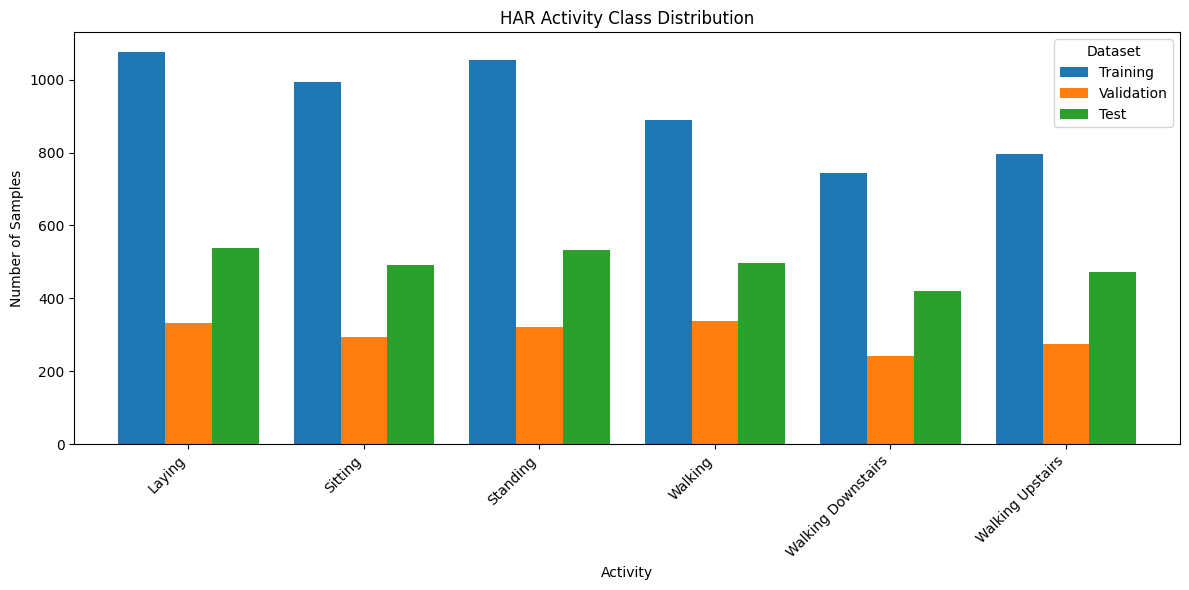

Activity class counts:


,Training,Validation,Test
Laying,1076,331,537
Sitting,993,293,491
Standing,1053,321,532
Walking,888,338,496
Walking Downstairs,744,242,420
Walking Upstairs,797,276,471


In [51]:
# Plot HAR activity class distribution

# Convert numerical activity labels into activity names
train_distribution = pd.Series(y_train_split).map(activity_labels).value_counts()
val_distribution = pd.Series(y_val).map(activity_labels).value_counts()
test_distribution = pd.Series(y_test).map(activity_labels).value_counts()

# Combine the distributions into one DataFrame
class_distribution = pd.DataFrame({
    "Training": train_distribution,
    "Validation": val_distribution,
    "Test": test_distribution
}).fillna(0)

# Plot class distribution
class_distribution.plot(
    kind="bar",
    figsize=(12, 6),
    width=0.8
)

plt.title("HAR Activity Class Distribution")
plt.xlabel("Activity")
plt.ylabel("Number of Samples")
plt.xticks(rotation=45, ha="right")
plt.legend(title="Dataset")
plt.tight_layout()
plt.show()

# Display exact counts
print("Activity class counts:")
display(class_distribution.astype(int))

In [52]:
print("RNN hidden size:", my_rnn.hidden_size)
print("LSTM hidden size:", my_lstm.hidden_size)
print("GRU hidden size:", my_gru.hidden_size)

RNN hidden size: 32
LSTM hidden size: 32
GRU hidden size: 32


In [53]:
input_size = 9
hidden_size = 64
num_classes = 6
sequence_length = 128

learning_rate = 0.001
batch_size = 64
num_epochs = 30

seeds = [42, 123, 2026]

print("Input size:", input_size)
print("Hidden size:", hidden_size)
print("Number of classes:", num_classes)
print("Sequence length:", sequence_length)
print("Seeds:", seeds)

Input size: 9
Hidden size: 64
Number of classes: 6
Sequence length: 128
Seeds: [42, 123, 2026]


In [54]:
my_rnn = MyRNNCell(input_size, hidden_size)
my_lstm = MyLSTMCell(input_size, hidden_size)
my_gru = MyGRUCell(input_size, hidden_size)

print("RNN hidden size:", my_rnn.hidden_size)
print("LSTM hidden size:", my_lstm.hidden_size)
print("GRU hidden size:", my_gru.hidden_size)

assert my_rnn.hidden_size == 64
assert my_lstm.hidden_size == 64
assert my_gru.hidden_size == 64

print("All three custom cells are configured with h = 64!")

RNN hidden size: 64
LSTM hidden size: 64
GRU hidden size: 64
All three custom cells are configured with h = 64!


In [55]:
# Build the three sequence classifiers
class RNNClassifier(nn.Module):
    def __init__(self, input_size=9, hidden_size=64, num_classes=6):
        super().__init__()
        self.hidden_size = hidden_size
        self.rnn_cell = MyRNNCell(input_size, hidden_size)
        self.fc = nn.Linear(hidden_size, num_classes)

    def forward(self, x):
        batch_size = x.size(0)

        h = x.new_zeros(batch_size, self.hidden_size)

        for t in range(x.size(1)):
            h = self.rnn_cell(x[:, t, :], h)

        return self.fc(h)


class LSTMClassifier(nn.Module):
    def __init__(self, input_size=9, hidden_size=64, num_classes=6):
        super().__init__()
        self.hidden_size = hidden_size
        self.lstm_cell = MyLSTMCell(input_size, hidden_size)
        self.fc = nn.Linear(hidden_size, num_classes)

    def forward(self, x):
        batch_size = x.size(0)

        h = x.new_zeros(batch_size, self.hidden_size)
        c = x.new_zeros(batch_size, self.hidden_size)

        for t in range(x.size(1)):
            h, c = self.lstm_cell(x[:, t, :], (h, c))

        return self.fc(h)


class GRUClassifier(nn.Module):
    def __init__(self, input_size=9, hidden_size=64, num_classes=6):
        super().__init__()
        self.hidden_size = hidden_size
        self.gru_cell = MyGRUCell(input_size, hidden_size)
        self.fc = nn.Linear(hidden_size, num_classes)

    def forward(self, x):
        batch_size = x.size(0)

        h = x.new_zeros(batch_size, self.hidden_size)

        for t in range(x.size(1)):
            h = self.gru_cell(x[:, t, :], h)

        return self.fc(h)

In [56]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

models = {
    "RNN": RNNClassifier(input_size, hidden_size, num_classes),
    "LSTM": LSTMClassifier(input_size, hidden_size, num_classes),
    "GRU": GRUClassifier(input_size, hidden_size, num_classes)
}

for name, model in models.items():
    model = model.to(device)

    # Test using one batch from the training data
    with torch.no_grad():
        sample_output = model(X_train_tensor[:4].to(device))

    print(
        name,
        "| Output shape:", tuple(sample_output.shape),
        "| Parameters:", sum(p.numel() for p in model.parameters())
    )

    assert sample_output.shape == (4, num_classes)

print("\nAll three sequence classifiers passed the output-shape test!")
print("Device:", device)

RNN | Output shape: (4, 6) | Parameters: 5190
LSTM | Output shape: (4, 6) | Parameters: 19590
GRU | Output shape: (4, 6) | Parameters: 14790

All three sequence classifiers passed the output-shape test!
Device: cuda


In [57]:
for name, model in models.items():
    total = sum(p.numel() for p in model.parameters())

    recurrent = sum(
        p.numel()
        for name_p, p in model.named_parameters()
        if name_p != "fc.weight" and name_p != "fc.bias"
    )

    classifier = sum(p.numel() for p in model.fc.parameters())

    print(f"\n{name}")
    print("Recurrent parameters:", recurrent)
    print("Classifier parameters:", classifier)
    print("Total parameters:", total)

    assert total == recurrent + classifier


RNN
Recurrent parameters: 4800
Classifier parameters: 390
Total parameters: 5190

LSTM
Recurrent parameters: 19200
Classifier parameters: 390
Total parameters: 19590

GRU
Recurrent parameters: 14400
Classifier parameters: 390
Total parameters: 14790


In [58]:
import copy
import time
import random
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


def train_model(model, seed, epochs=30, batch_size=64, lr=0.001):

    set_seed(seed)

    model = model.to(device)

    train_dataset = TensorDataset(
        X_train_tensor, y_train_tensor
    )

    train_loader = DataLoader(
        train_dataset,
        batch_size=batch_size,
        shuffle=True
    )

    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)

    history = {
        "train_loss": [],
        "val_loss": [],
        "val_accuracy": [],
        "epoch_time": []
    }

    best_val_loss = float("inf")
    best_state = None

    for epoch in range(epochs):

        start_time = time.time()

        model.train()
        running_loss = 0.0

        for inputs, targets in train_loader:

            inputs = inputs.to(device)
            targets = targets.to(device).long()

            optimizer.zero_grad()

            outputs = model(inputs)
            loss = criterion(outputs, targets)

            loss.backward()
            optimizer.step()

            running_loss += loss.item() * inputs.size(0)

        train_loss = running_loss / len(train_dataset)

        # Validation
        model.eval()

        val_loss_total = 0.0
        correct = 0
        total = 0

        with torch.no_grad():

            for start in range(0, len(X_val_tensor), batch_size):

                inputs = X_val_tensor[start:start + batch_size].to(device)
                targets = y_val_tensor[start:start + batch_size].to(device).long()

                outputs = model(inputs)
                loss = criterion(outputs, targets)

                val_loss_total += loss.item() * inputs.size(0)

                predictions = outputs.argmax(dim=1)

                correct += (predictions == targets).sum().item()
                total += targets.size(0)

        val_loss = val_loss_total / total
        val_accuracy = correct / total

        epoch_time = time.time() - start_time

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["val_accuracy"].append(val_accuracy)
        history["epoch_time"].append(epoch_time)

        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_state = copy.deepcopy(model.state_dict())

        print(
            f"Epoch [{epoch+1:02d}/{epochs}] "
            f"Train Loss: {train_loss:.4f} | "
            f"Val Loss: {val_loss:.4f} | "
            f"Val Accuracy: {val_accuracy:.4f} | "
            f"Time: {epoch_time:.2f}s"
        )

    model.load_state_dict(best_state)

    return model, history

In [59]:
set_seed(42)

test_model = RNNClassifier(
    input_size=9,
    hidden_size=64,
    num_classes=6
)

test_model, test_history = train_model(
    test_model,
    seed=42,
    epochs=30,
    batch_size=64,
    lr=0.001
)

Epoch [01/30] Train Loss: 1.1922 | Val Loss: 0.8810 | Val Accuracy: 0.6513 | Time: 5.06s
Epoch [02/30] Train Loss: 0.7249 | Val Loss: 0.6756 | Val Accuracy: 0.7135 | Time: 3.94s
Epoch [03/30] Train Loss: 0.6462 | Val Loss: 0.5728 | Val Accuracy: 0.7585 | Time: 3.72s
Epoch [04/30] Train Loss: 0.6392 | Val Loss: 0.6105 | Val Accuracy: 0.7668 | Time: 4.41s
Epoch [05/30] Train Loss: 0.7168 | Val Loss: 0.6080 | Val Accuracy: 0.7701 | Time: 3.84s
Epoch [06/30] Train Loss: 0.5652 | Val Loss: 0.5616 | Val Accuracy: 0.7762 | Time: 3.67s
Epoch [07/30] Train Loss: 0.5341 | Val Loss: 0.5053 | Val Accuracy: 0.8057 | Time: 4.05s
Epoch [08/30] Train Loss: 0.4969 | Val Loss: 0.5619 | Val Accuracy: 0.8062 | Time: 4.17s
Epoch [09/30] Train Loss: 0.4597 | Val Loss: 0.4174 | Val Accuracy: 0.8762 | Time: 3.72s
Epoch [10/30] Train Loss: 0.4137 | Val Loss: 0.4035 | Val Accuracy: 0.8934 | Time: 3.75s
Epoch [11/30] Train Loss: 0.4486 | Val Loss: 0.6659 | Val Accuracy: 0.7901 | Time: 4.40s
Epoch [12/30] Train L

In [60]:
# Train all three models with three seeds

In [61]:
from sklearn.metrics import accuracy_score, f1_score
import pandas as pd
import copy
import time

# Model constructors
model_factories = {
    "RNN": RNNClassifier,
    "LSTM": LSTMClassifier,
    "GRU": GRUClassifier
}

results = []
trained_models = {}
training_histories = {}

def evaluate_model(model, X, y, batch_size=64):

    model.eval()

    all_predictions = []
    all_targets = []

    with torch.no_grad():
        for start in range(0, len(X), batch_size):

            inputs = X[start:start + batch_size].to(device)
            targets = y[start:start + batch_size].to(device).long()

            outputs = model(inputs)
            predictions = outputs.argmax(dim=1)

            all_predictions.extend(predictions.cpu().numpy())
            all_targets.extend(targets.cpu().numpy())

    accuracy = accuracy_score(all_targets, all_predictions)

    macro_f1 = f1_score(
        all_targets,
        all_predictions,
        average="macro"
    )

    return accuracy, macro_f1


for model_name, model_class in model_factories.items():

    for seed in seeds:

        print("\n" + "=" * 60)
        print(f"Training {model_name} | Seed: {seed}")
        print("=" * 60)

        # Seed before model initialization
        set_seed(seed)

        model = model_class(
            input_size=input_size,
            hidden_size=hidden_size,
            num_classes=num_classes
        )

        model, history = train_model(
            model,
            seed=seed,
            epochs=num_epochs,
            batch_size=batch_size,
            lr=learning_rate
        )

        # Evaluate the best validation checkpoint on test data
        test_accuracy, test_macro_f1 = evaluate_model(
            model,
            X_test_tensor,
            y_test_tensor
        )

        parameter_count = sum(
            p.numel() for p in model.parameters()
        )

        best_epoch = int(np.argmin(history["val_loss"])) + 1

        average_epoch_time = np.mean(history["epoch_time"])

        results.append({
            "Model": model_name,
            "Seed": seed,
            "Test Accuracy": test_accuracy,
            "Macro F1": test_macro_f1,
            "Parameters": parameter_count,
            "Seconds per Epoch": average_epoch_time,
            "Best Epoch": best_epoch,
            "Best Validation Loss": min(history["val_loss"])
        })

        trained_models[(model_name, seed)] = model
        training_histories[(model_name, seed)] = history

        print(f"\nTest Accuracy: {test_accuracy:.4f}")
        print(f"Test Macro F1: {test_macro_f1:.4f}")
        print(f"Best Epoch: {best_epoch}")
        print(f"Average seconds per epoch: {average_epoch_time:.2f}")


results_df = pd.DataFrame(results)

print("\n\nCOMPLETE EXPERIMENT RESULTS")
display(results_df)


Training RNN | Seed: 42
Epoch [01/30] Train Loss: 1.1922 | Val Loss: 0.8810 | Val Accuracy: 0.6513 | Time: 3.71s
Epoch [02/30] Train Loss: 0.7249 | Val Loss: 0.6756 | Val Accuracy: 0.7135 | Time: 3.99s
Epoch [03/30] Train Loss: 0.6462 | Val Loss: 0.5728 | Val Accuracy: 0.7585 | Time: 4.19s
Epoch [04/30] Train Loss: 0.6392 | Val Loss: 0.6105 | Val Accuracy: 0.7668 | Time: 3.71s
Epoch [05/30] Train Loss: 0.7168 | Val Loss: 0.6080 | Val Accuracy: 0.7701 | Time: 3.68s
Epoch [06/30] Train Loss: 0.5652 | Val Loss: 0.5616 | Val Accuracy: 0.7762 | Time: 4.58s
Epoch [07/30] Train Loss: 0.5341 | Val Loss: 0.5053 | Val Accuracy: 0.8057 | Time: 3.94s
Epoch [08/30] Train Loss: 0.4969 | Val Loss: 0.5619 | Val Accuracy: 0.8062 | Time: 3.71s
Epoch [09/30] Train Loss: 0.4597 | Val Loss: 0.4174 | Val Accuracy: 0.8762 | Time: 4.52s
Epoch [10/30] Train Loss: 0.4137 | Val Loss: 0.4035 | Val Accuracy: 0.8934 | Time: 4.07s
Epoch [11/30] Train Loss: 0.4486 | Val Loss: 0.6659 | Val Accuracy: 0.7901 | Time: 3.

,Model,Seed,Test Accuracy,Macro F1,Parameters,Seconds per Epoch,Best Epoch,Best Validation Loss
0,RNN,42,0.851035,0.847149,5190,3.954931,24,0.196119
1,RNN,123,0.857822,0.856384,5190,3.992245,29,0.228439
2,RNN,2026,0.791653,0.784125,5190,4.007188,10,0.396191
3,LSTM,42,0.917883,0.917878,19590,8.228601,16,0.099731
4,LSTM,123,0.917204,0.917983,19590,8.290926,28,0.149669
5,LSTM,2026,0.897862,0.898666,19590,8.522851,27,0.078910
6,GRU,42,0.914829,0.913242,14790,14.628330,26,0.084489
7,GRU,123,0.898202,0.896600,14790,14.558383,8,0.145625
8,GRU,2026,0.903970,0.903595,14790,15.065798,15,0.072683


In [62]:
# Calculate mean and standard deviation

summary_df = results_df.groupby("Model").agg(
    Accuracy_Mean=("Test Accuracy", "mean"),
    Accuracy_Std=("Test Accuracy", "std"),
    Macro_F1_Mean=("Macro F1", "mean"),
    Macro_F1_Std=("Macro F1", "std"),
    Parameters=("Parameters", "first"),
    Seconds_Per_Epoch=("Seconds per Epoch", "mean")
).reset_index()

display(summary_df.round(4))

,Model,Accuracy_Mean,Accuracy_Std,Macro_F1_Mean,Macro_F1_Std,Parameters,Seconds_Per_Epoch
0,GRU,0.9057,0.0084,0.9045,0.0084,14790,14.7508
1,LSTM,0.9110,0.0114,0.9115,0.0111,19590,8.3475
2,RNN,0.8335,0.0364,0.8292,0.0393,5190,3.9848


Generate and save the best HAR model's confusion matrix

Selected model: ('GRU', 2026)
Best validation loss: 0.07268319814789137
Class IDs: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5)]
Class names: ['Walking', 'Walking Upstairs', 'Walking Downstairs', 'Sitting', 'Standing', 'Laying']


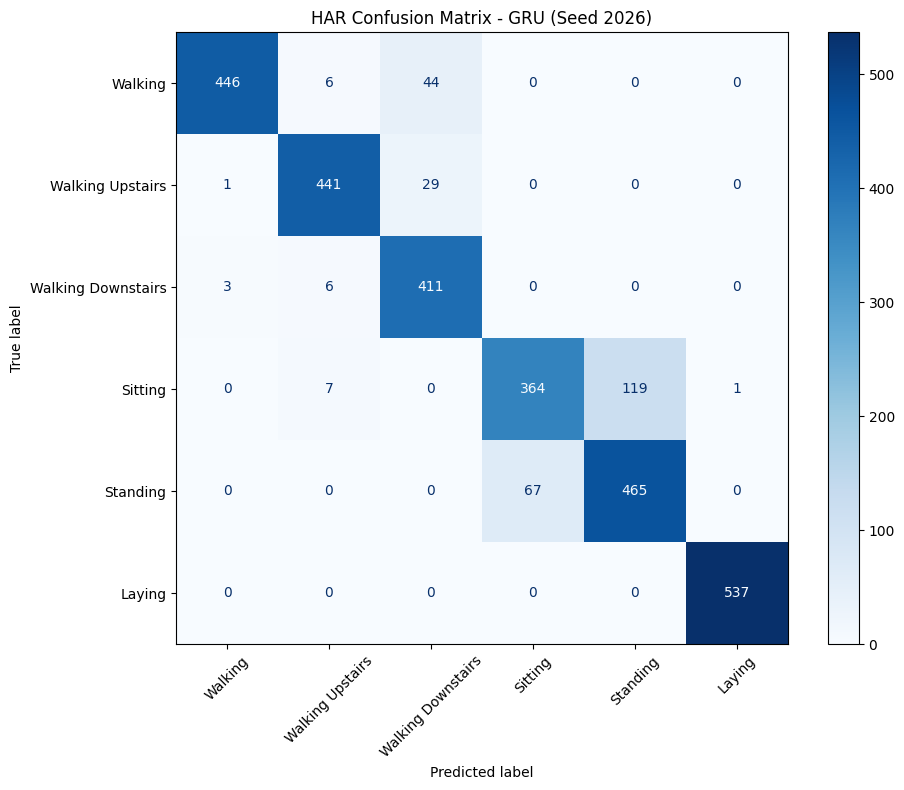


Classification Report:
                    precision    recall  f1-score   support

           Walking     0.9911    0.8992    0.9429       496
  Walking Upstairs     0.9587    0.9363    0.9474       471
Walking Downstairs     0.8492    0.9786    0.9093       420
           Sitting     0.8445    0.7413    0.7896       491
          Standing     0.7962    0.8741    0.8333       532
            Laying     0.9981    1.0000    0.9991       537

          accuracy                         0.9040      2947
         macro avg     0.9063    0.9049    0.9036      2947
      weighted avg     0.9074    0.9040    0.9037      2947

Confusion matrix saved as HAR_Confusion_Matrix.png


In [65]:
from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report
)

# Select best individual run based on validation loss
best_result = min(
    results,
    key=lambda row: row["Best Validation Loss"]
)

best_key = (best_result["Model"], best_result["Seed"])
best_model = trained_models[best_key]

print("Selected model:", best_key)
print("Best validation loss:", best_result["Best Validation Loss"])

# Generate test predictions
best_model.eval()

all_predictions = []
all_targets = []

with torch.no_grad():
    for start in range(0, len(X_test_tensor), batch_size):

        inputs = X_test_tensor[start:start + batch_size].to(device)
        targets = y_test_tensor[start:start + batch_size].to(device).long()

        outputs = best_model(inputs)
        predictions = outputs.argmax(dim=1)

        all_predictions.extend(predictions.cpu().numpy())
        all_targets.extend(targets.cpu().numpy())

# Activity labels
class_ids = sorted(np.unique(all_targets))

class_names = [
    activity_labels[int(class_id) + 1]
    for class_id in class_ids
]

print("Class IDs:", class_ids)
print("Class names:", class_names)

# Confusion matrix
cm = confusion_matrix(
    all_targets,
    all_predictions,
    labels=class_ids
)

fig, ax = plt.subplots(figsize=(10, 8))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

disp.plot(
    cmap="Blues",
    values_format="d",
    xticks_rotation=45,
    ax=ax
)

plt.title("HAR Confusion Matrix - GRU (Seed 2026)")
plt.tight_layout()

# Save high-resolution figure
plt.savefig(
    "HAR_Confusion_Matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("\nClassification Report:")
print(
    classification_report(
        all_targets,
        all_predictions,
        labels=class_ids,
        target_names=class_names,
        digits=4
    )
)

print("Confusion matrix saved as HAR_Confusion_Matrix.png")

Adding problem: learning curves at T=200

Hidden size: 64 (same as the HAR experiments).
Training samples: 10,000.
Validation samples: 1,000.
Test samples: 1,000.
Model seeds: 42, 123, 2026.

In [66]:
from torch.utils.data import TensorDataset, DataLoader

# Adding problem configuration
T = 200
n_train = 10000
n_val = 1000
n_test = 1000

# Generate the same datasets for all three models
X_add_train, y_add_train = make_adding(n_train, T, seed=0)
X_add_val, y_add_val = make_adding(n_val, T, seed=1)
X_add_test, y_add_test = make_adding(n_test, T, seed=2)

# Convert NumPy arrays to PyTorch tensors
X_add_train = torch.tensor(X_add_train, dtype=torch.float32)
y_add_train = torch.tensor(y_add_train, dtype=torch.float32).unsqueeze(1)

X_add_val = torch.tensor(X_add_val, dtype=torch.float32)
y_add_val = torch.tensor(y_add_val, dtype=torch.float32).unsqueeze(1)

X_add_test = torch.tensor(X_add_test, dtype=torch.float32)
y_add_test = torch.tensor(y_add_test, dtype=torch.float32).unsqueeze(1)

# Create datasets
train_dataset = TensorDataset(X_add_train, y_add_train)
val_dataset = TensorDataset(X_add_val, y_add_val)
test_dataset = TensorDataset(X_add_test, y_add_test)

print("Training data:", X_add_train.shape, y_add_train.shape)
print("Validation data:", X_add_val.shape, y_add_val.shape)
print("Test data:", X_add_test.shape, y_add_test.shape)

Training data: torch.Size([10000, 200, 2]) torch.Size([10000, 1])
Validation data: torch.Size([1000, 200, 2]) torch.Size([1000, 1])
Test data: torch.Size([1000, 200, 2]) torch.Size([1000, 1])


Define adding-problem regression models

In [67]:
class RNNAdding(nn.Module):
    def __init__(self, input_size=2, hidden_size=64):
        super().__init__()
        self.hidden_size = hidden_size
        self.rnn_cell = MyRNNCell(input_size, hidden_size)
        self.fc = nn.Linear(hidden_size, 1)

    def forward(self, x):
        h = x.new_zeros(x.size(0), self.hidden_size)

        for t in range(x.size(1)):
            h = self.rnn_cell(x[:, t, :], h)

        return self.fc(h)


class LSTMAdding(nn.Module):
    def __init__(self, input_size=2, hidden_size=64):
        super().__init__()
        self.hidden_size = hidden_size
        self.lstm_cell = MyLSTMCell(input_size, hidden_size)
        self.fc = nn.Linear(hidden_size, 1)

    def forward(self, x):
        h = x.new_zeros(x.size(0), self.hidden_size)
        c = x.new_zeros(x.size(0), self.hidden_size)

        for t in range(x.size(1)):
            h, c = self.lstm_cell(x[:, t, :], (h, c))

        return self.fc(h)


class GRUAdding(nn.Module):
    def __init__(self, input_size=2, hidden_size=64):
        super().__init__()
        self.hidden_size = hidden_size
        self.gru_cell = MyGRUCell(input_size, hidden_size)
        self.fc = nn.Linear(hidden_size, 1)

    def forward(self, x):
        h = x.new_zeros(x.size(0), self.hidden_size)

        for t in range(x.size(1)):
            h = self.gru_cell(x[:, t, :], h)

        return self.fc(h)


# Verify model output dimensions
for model_class in [RNNAdding, LSTMAdding, GRUAdding]:
    model = model_class().to(device)
    sample_output = model(X_add_train[:4].to(device))
    print(model_class.__name__, sample_output.shape)

RNNAdding torch.Size([4, 1])
LSTMAdding torch.Size([4, 1])
GRUAdding torch.Size([4, 1])


Define the training function

In [68]:
def train_adding_model(model, seed, epochs=30, batch_size=64, lr=0.001):

    torch.manual_seed(seed)
    np.random.seed(seed)

    model = model.to(device)

    train_loader = DataLoader(
        train_dataset,
        batch_size=batch_size,
        shuffle=True
    )

    val_loader = DataLoader(
        val_dataset,
        batch_size=batch_size,
        shuffle=False
    )

    criterion = nn.MSELoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)

    history = {
        "train_loss": [],
        "val_loss": []
    }

    best_val_loss = float("inf")
    best_model_state = None

    for epoch in range(epochs):

        # Training
        model.train()
        train_loss = 0.0

        for xb, yb in train_loader:
            xb = xb.to(device)
            yb = yb.to(device)

            optimizer.zero_grad()

            predictions = model(xb)
            loss = criterion(predictions, yb)

            loss.backward()
            optimizer.step()

            train_loss += loss.item() * xb.size(0)

        train_loss /= len(train_dataset)

        # Validation
        model.eval()
        val_loss = 0.0

        with torch.no_grad():
            for xb, yb in val_loader:
                xb = xb.to(device)
                yb = yb.to(device)

                predictions = model(xb)
                loss = criterion(predictions, yb)

                val_loss += loss.item() * xb.size(0)

        val_loss /= len(val_dataset)

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)

        # Save best validation checkpoint
        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_model_state = {
                key: value.detach().cpu().clone()
                for key, value in model.state_dict().items()
            }

        print(
            f"Seed {seed} | Epoch {epoch + 1:02d}/{epochs} | "
            f"Train MSE: {train_loss:.6f} | "
            f"Val MSE: {val_loss:.6f}"
        )

    model.load_state_dict(best_model_state)

    return model, history, best_val_loss

Train RNN, LSTM and GRU

In [69]:
adding_models = {
    "RNN": RNNAdding,
    "LSTM": LSTMAdding,
    "GRU": GRUAdding
}

adding_results = {}

for model_name, model_class in adding_models.items():

    for seed in seeds:

        print(f"\n{'='*60}")
        print(f"Training {model_name} | Seed {seed}")
        print(f"{'='*60}")

        model = model_class(
            input_size=2,
            hidden_size=64
        )

        trained_model, history, best_val_loss = train_adding_model(
            model=model,
            seed=seed,
            epochs=30,
            batch_size=64,
            lr=0.001
        )

        adding_results[(model_name, seed)] = {
            "model": trained_model,
            "history": history,
            "best_val_loss": best_val_loss
        }

print("\nAll nine adding-problem experiments completed!")


Training RNN | Seed 42
Seed 42 | Epoch 01/30 | Train MSE: 0.225355 | Val MSE: 0.160859
Seed 42 | Epoch 02/30 | Train MSE: 0.169607 | Val MSE: 0.160302
Seed 42 | Epoch 03/30 | Train MSE: 0.169283 | Val MSE: 0.161445
Seed 42 | Epoch 04/30 | Train MSE: 0.169437 | Val MSE: 0.160904
Seed 42 | Epoch 05/30 | Train MSE: 0.169985 | Val MSE: 0.163419
Seed 42 | Epoch 06/30 | Train MSE: 0.169567 | Val MSE: 0.160743
Seed 42 | Epoch 07/30 | Train MSE: 0.169384 | Val MSE: 0.159865
Seed 42 | Epoch 08/30 | Train MSE: 0.169580 | Val MSE: 0.160981
Seed 42 | Epoch 09/30 | Train MSE: 0.169844 | Val MSE: 0.161097
Seed 42 | Epoch 10/30 | Train MSE: 0.169102 | Val MSE: 0.159562
Seed 42 | Epoch 11/30 | Train MSE: 0.169640 | Val MSE: 0.162103
Seed 42 | Epoch 12/30 | Train MSE: 0.169076 | Val MSE: 0.162296
Seed 42 | Epoch 13/30 | Train MSE: 0.169069 | Val MSE: 0.159847
Seed 42 | Epoch 14/30 | Train MSE: 0.170040 | Val MSE: 0.160399
Seed 42 | Epoch 15/30 | Train MSE: 0.169004 | Val MSE: 0.163006
Seed 42 | Epoch 

Plot learning curves at T=200

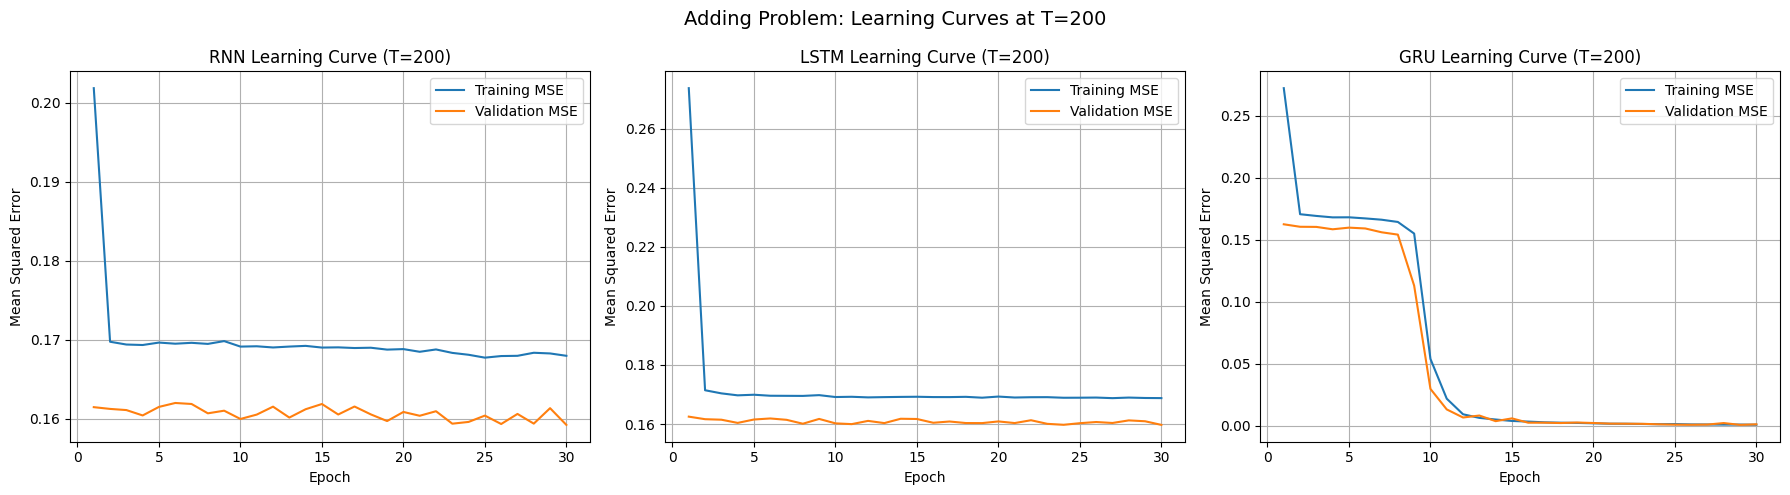

Learning curves saved as Adding_Learning_Curves_T200.png


In [70]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, model_name in zip(axes, ["RNN", "LSTM", "GRU"]):

    train_curves = []
    val_curves = []

    for seed in seeds:
        history = adding_results[(model_name, seed)]["history"]

        train_curves.append(history["train_loss"])
        val_curves.append(history["val_loss"])

    mean_train = np.mean(train_curves, axis=0)
    mean_val = np.mean(val_curves, axis=0)

    epochs = range(1, len(mean_train) + 1)

    ax.plot(epochs, mean_train, label="Training MSE")
    ax.plot(epochs, mean_val, label="Validation MSE")

    ax.set_title(f"{model_name} Learning Curve (T=200)")
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Mean Squared Error")
    ax.legend()
    ax.grid(True)

plt.suptitle("Adding Problem: Learning Curves at T=200", fontsize=14)
plt.tight_layout()

plt.savefig("Adding_Learning_Curves_T200.png", dpi=300, bbox_inches="tight")
plt.show()

print("Learning curves saved as Adding_Learning_Curves_T200.png")

In [71]:
def evaluate_adding_model(model, test_dataset, batch_size=64):

    test_loader = DataLoader(
        test_dataset,
        batch_size=batch_size,
        shuffle=False
    )

    criterion = nn.MSELoss()
    model.eval()

    total_loss = 0.0

    with torch.no_grad():
        for xb, yb in test_loader:
            xb = xb.to(device)
            yb = yb.to(device)

            predictions = model(xb)
            loss = criterion(predictions, yb)

            total_loss += loss.item() * xb.size(0)

    return total_loss / len(test_dataset)


# Evaluate all nine trained models
test_mse_results = []

for (model_name, seed), result in adding_results.items():

    model = result["model"]

    test_mse = evaluate_adding_model(
        model,
        test_dataset
    )

    test_mse_results.append({
        "Model": model_name,
        "Seed": seed,
        "Best Validation MSE": result["best_val_loss"],
        "Test MSE": test_mse
    })

test_mse_df = pd.DataFrame(test_mse_results)

print(test_mse_df.round(6).to_string(index=False))

Model  Seed  Best Validation MSE  Test MSE
  RNN    42             0.159097  0.167443
  RNN   123             0.158315  0.165832
  RNN  2026             0.156347  0.163733
 LSTM    42             0.159748  0.168557
 LSTM   123             0.159580  0.168294
 LSTM  2026             0.159714  0.168160
  GRU    42             0.000498  0.000390
  GRU   123             0.000524  0.000450
  GRU  2026             0.000367  0.000336


Prepare the sequence-length experiment

In [72]:
sequence_lengths = [50, 100, 200, 400]

adding_datasets = {}

for T in sequence_lengths:

    if T == 200:
        # Reuse the datasets already generated
        adding_datasets[T] = {
            "train": train_dataset,
            "val": val_dataset,
            "test": test_dataset
        }

    else:
        X_train, y_train = make_adding(10000, T, seed=0)
        X_val, y_val = make_adding(1000, T, seed=1)
        X_test, y_test = make_adding(1000, T, seed=2)

        adding_datasets[T] = {
            "train": TensorDataset(
                torch.tensor(X_train, dtype=torch.float32),
                torch.tensor(y_train, dtype=torch.float32).unsqueeze(1)
            ),
            "val": TensorDataset(
                torch.tensor(X_val, dtype=torch.float32),
                torch.tensor(y_val, dtype=torch.float32).unsqueeze(1)
            ),
            "test": TensorDataset(
                torch.tensor(X_test, dtype=torch.float32),
                torch.tensor(y_test, dtype=torch.float32).unsqueeze(1)
            )
        }

    print(
        f"T={T}:",
        adding_datasets[T]["train"].tensors[0].shape,
        adding_datasets[T]["val"].tensors[0].shape,
        adding_datasets[T]["test"].tensors[0].shape
    )

T=50: torch.Size([10000, 50, 2]) torch.Size([1000, 50, 2]) torch.Size([1000, 50, 2])
T=100: torch.Size([10000, 100, 2]) torch.Size([1000, 100, 2]) torch.Size([1000, 100, 2])
T=200: torch.Size([10000, 200, 2]) torch.Size([1000, 200, 2]) torch.Size([1000, 200, 2])
T=400: torch.Size([10000, 400, 2]) torch.Size([1000, 400, 2]) torch.Size([1000, 400, 2])


Create a training function for different sequence lengths

In [73]:
def train_adding_model_variable(
    model,
    train_data,
    val_data,
    seed,
    epochs=30,
    batch_size=64,
    lr=0.001
):
    torch.manual_seed(seed)
    np.random.seed(seed)

    model = model.to(device)

    train_loader = DataLoader(
        train_data,
        batch_size=batch_size,
        shuffle=True
    )

    val_loader = DataLoader(
        val_data,
        batch_size=batch_size,
        shuffle=False
    )

    criterion = nn.MSELoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)

    history = {
        "train_loss": [],
        "val_loss": []
    }

    best_val_loss = float("inf")
    best_model_state = None

    for epoch in range(epochs):

        model.train()
        train_loss = 0.0

        for xb, yb in train_loader:
            xb = xb.to(device)
            yb = yb.to(device)

            optimizer.zero_grad()

            predictions = model(xb)
            loss = criterion(predictions, yb)

            loss.backward()
            optimizer.step()

            train_loss += loss.item() * xb.size(0)

        train_loss /= len(train_data)

        model.eval()
        val_loss = 0.0

        with torch.no_grad():
            for xb, yb in val_loader:
                xb = xb.to(device)
                yb = yb.to(device)

                predictions = model(xb)
                loss = criterion(predictions, yb)

                val_loss += loss.item() * xb.size(0)

        val_loss /= len(val_data)

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)

        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_model_state = {
                key: value.detach().cpu().clone()
                for key, value in model.state_dict().items()
            }

    model.load_state_dict(best_model_state)

    return model, history, best_val_loss

In [75]:
adding_all_results = {}

# Reuse the completed T=200 experiments
for (model_name, seed), result in adding_results.items():
    adding_all_results[(model_name, seed, 200)] = result

# Train the remaining sequence lengths
for T in [50, 100, 400]:

    train_data = adding_datasets[T]["train"]
    val_data = adding_datasets[T]["val"]

    for model_name, model_class in adding_models.items():

        for seed in seeds:

            print(f"\nTraining {model_name} | T={T} | Seed={seed}")

            # Set seed before model initialization
            torch.manual_seed(seed)
            np.random.seed(seed)

            model = model_class(
                input_size=2,
                hidden_size=64
            )

            trained_model, history, best_val_loss = train_adding_model_variable(
                model=model,
                train_data=train_data,
                val_data=val_data,
                seed=seed,
                epochs=30,
                batch_size=64,
                lr=0.001
            )

            adding_all_results[(model_name, seed, T)] = {
                "model": trained_model,
                "history": history,
                "best_val_loss": best_val_loss
            }

print("\nAll sequence-length experiments completed!")
print("Total experiments:", len(adding_all_results))


Training RNN | T=50 | Seed=42

Training RNN | T=50 | Seed=123

Training RNN | T=50 | Seed=2026

Training LSTM | T=50 | Seed=42

Training LSTM | T=50 | Seed=123

Training LSTM | T=50 | Seed=2026

Training GRU | T=50 | Seed=42

Training GRU | T=50 | Seed=123

Training GRU | T=50 | Seed=2026

Training RNN | T=100 | Seed=42

Training RNN | T=100 | Seed=123

Training RNN | T=100 | Seed=2026


KeyboardInterrupt: 

In [76]:
def train_adding_model_fast(
    model,
    train_data,
    val_data,
    seed,
    epochs=30,
    batch_size=128,
    lr=0.001,
    patience=5
):
    torch.manual_seed(seed)
    np.random.seed(seed)

    model = model.to(device)

    train_loader = DataLoader(
        train_data,
        batch_size=batch_size,
        shuffle=True
    )

    val_loader = DataLoader(
        val_data,
        batch_size=batch_size,
        shuffle=False
    )

    criterion = nn.MSELoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)

    history = {"train_loss": [], "val_loss": []}

    best_val_loss = float("inf")
    best_model_state = None
    epochs_without_improvement = 0

    for epoch in range(epochs):

        model.train()
        train_loss = 0.0

        for xb, yb in train_loader:
            xb, yb = xb.to(device), yb.to(device)

            optimizer.zero_grad()
            predictions = model(xb)
            loss = criterion(predictions, yb)
            loss.backward()
            optimizer.step()

            train_loss += loss.item() * xb.size(0)

        train_loss /= len(train_data)

        model.eval()
        val_loss = 0.0

        with torch.no_grad():
            for xb, yb in val_loader:
                xb, yb = xb.to(device), yb.to(device)

                predictions = model(xb)
                loss = criterion(predictions, yb)

                val_loss += loss.item() * xb.size(0)

        val_loss /= len(val_data)

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)

        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_model_state = {
                k: v.detach().cpu().clone()
                for k, v in model.state_dict().items()
            }
            epochs_without_improvement = 0
        else:
            epochs_without_improvement += 1

        print(
            f"Epoch {epoch+1:02d} | "
            f"Train MSE: {train_loss:.6f} | "
            f"Val MSE: {val_loss:.6f}"
        )

        if epochs_without_improvement >= patience:
            print("Early stopping triggered.")
            break

    model.load_state_dict(best_model_state)

    return model, history, best_val_loss

In [77]:
for T in [50, 100, 400]:

    train_data = adding_datasets[T]["train"]
    val_data = adding_datasets[T]["val"]

    for model_name, model_class in adding_models.items():

        for seed in seeds:

            result_key = (model_name, seed, T)

            if result_key in adding_all_results:
                print(f"Skipping completed: {result_key}")
                continue

            print(f"\nTraining {model_name} | T={T} | Seed={seed}")

            torch.manual_seed(seed)
            np.random.seed(seed)

            model = model_class(
                input_size=2,
                hidden_size=64
            )

            trained_model, history, best_val_loss = train_adding_model_fast(
                model=model,
                train_data=train_data,
                val_data=val_data,
                seed=seed,
                epochs=30,
                batch_size=128,
                lr=0.001,
                patience=5
            )

            adding_all_results[result_key] = {
                "model": trained_model,
                "history": history,
                "best_val_loss": best_val_loss
            }

print("\nExperiments currently stored:", len(adding_all_results))
print("Expected total:", 36)

Skipping completed: ('RNN', 42, 50)
Skipping completed: ('RNN', 123, 50)
Skipping completed: ('RNN', 2026, 50)
Skipping completed: ('LSTM', 42, 50)
Skipping completed: ('LSTM', 123, 50)
Skipping completed: ('LSTM', 2026, 50)
Skipping completed: ('GRU', 42, 50)
Skipping completed: ('GRU', 123, 50)
Skipping completed: ('GRU', 2026, 50)
Skipping completed: ('RNN', 42, 100)
Skipping completed: ('RNN', 123, 100)

Training RNN | T=100 | Seed=2026
Epoch 01 | Train MSE: 0.218281 | Val MSE: 0.161292
Epoch 02 | Train MSE: 0.167670 | Val MSE: 0.162054
Epoch 03 | Train MSE: 0.167461 | Val MSE: 0.160517
Epoch 04 | Train MSE: 0.167138 | Val MSE: 0.161079
Epoch 05 | Train MSE: 0.167182 | Val MSE: 0.162488
Epoch 06 | Train MSE: 0.167493 | Val MSE: 0.161282
Epoch 07 | Train MSE: 0.167522 | Val MSE: 0.160214
Epoch 08 | Train MSE: 0.167076 | Val MSE: 0.160906
Epoch 09 | Train MSE: 0.166899 | Val MSE: 0.160422
Epoch 10 | Train MSE: 0.166871 | Val MSE: 0.161922
Epoch 11 | Train MSE: 0.166992 | Val MSE: 0.1

Evaluate test MSE across all sequence lengths

In [78]:
adding_length_results = []

for (model_name, seed, T), result in adding_all_results.items():

    model = result["model"]
    test_data = adding_datasets[T]["test"]

    test_mse = evaluate_adding_model(
        model,
        test_data,
        batch_size=128
    )

    adding_length_results.append({
        "Model": model_name,
        "Sequence Length": T,
        "Seed": seed,
        "Best Validation MSE": result["best_val_loss"],
        "Test MSE": test_mse,
        "Solved": test_mse < 0.05
    })

adding_length_df = pd.DataFrame(adding_length_results)

adding_length_df = adding_length_df.sort_values(
    ["Sequence Length", "Model", "Seed"]
).reset_index(drop=True)

print(adding_length_df.round(6).to_string(index=False))

Model  Sequence Length  Seed  Best Validation MSE  Test MSE  Solved
  GRU               50    42             0.000531  0.000616    True
  GRU               50   123             0.000664  0.000791    True
  GRU               50  2026             0.000148  0.000168    True
 LSTM               50    42             0.000862  0.000976    True
 LSTM               50   123             0.000617  0.000603    True
 LSTM               50  2026             0.000965  0.000920    True
  RNN               50    42             0.008707  0.009904    True
  RNN               50   123             0.004107  0.003900    True
  RNN               50  2026             0.003167  0.003550    True
  GRU              100    42             0.002330  0.002079    True
  GRU              100   123             0.002866  0.002554    True
  GRU              100  2026             0.001581  0.001642    True
 LSTM              100    42             0.159615  0.171049   False
 LSTM              100   123             0.15902

Calculate mean and standard deviation

In [79]:
adding_summary = (
    adding_length_df
    .groupby(["Model", "Sequence Length"])
    .agg(
        Mean_Test_MSE=("Test MSE", "mean"),
        Std_Test_MSE=("Test MSE", "std"),
        Successful_Runs=("Solved", "sum")
    )
    .reset_index()
)

print(adding_summary.round(6).to_string(index=False))

Model  Sequence Length  Mean_Test_MSE  Std_Test_MSE  Successful_Runs
  GRU               50       0.000525      0.000321                3
  GRU              100       0.002092      0.000456                3
  GRU              200       0.000392      0.000057                3
  GRU              400       0.002359      0.000715                3
 LSTM               50       0.000833      0.000201                3
 LSTM              100       0.170128      0.000818                0
 LSTM              200       0.168337      0.000202                0
 LSTM              400       0.154081      0.000610                0
  RNN               50       0.005785      0.003572                3
  RNN              100       0.168151      0.001519                0
  RNN              200       0.165669      0.001860                0
  RNN              400       0.153255      0.000342                0


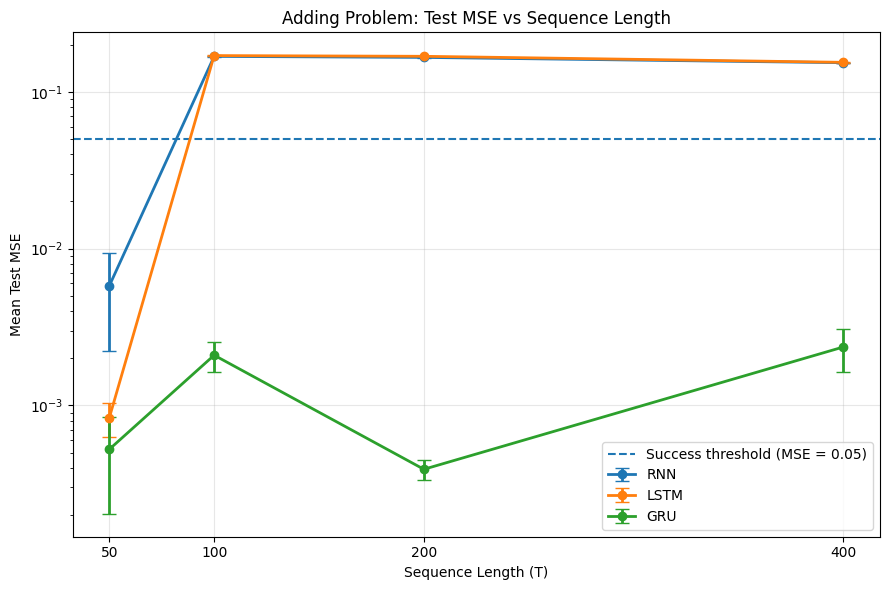

Plot saved as Adding_MSE_vs_Sequence_Length.png


In [81]:
plt.figure(figsize=(9, 6))

for model_name in ["RNN", "LSTM", "GRU"]:

    model_data = adding_summary[
        adding_summary["Model"] == model_name
    ].sort_values("Sequence Length")

    plt.errorbar(
        model_data["Sequence Length"],
        model_data["Mean_Test_MSE"],
        yerr=model_data["Std_Test_MSE"],
        marker="o",
        capsize=5,
        linewidth=2,
        label=model_name
    )

plt.axhline(
    y=0.05,
    linestyle="--",
    label="Success threshold (MSE = 0.05)"
)

plt.xlabel("Sequence Length (T)")
plt.ylabel("Mean Test MSE")
plt.title("Adding Problem: Test MSE vs Sequence Length")
plt.xticks([50, 100, 200, 400])
plt.yscale("log")
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(
    "Adding_MSE_vs_Sequence_Length.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

print("Plot saved as Adding_MSE_vs_Sequence_Length.png")

Gradient norm versus time step

In [82]:
def calculate_hidden_gradient_norms(model, x, y, model_name):

    model.eval()
    model.zero_grad(set_to_none=True)

    x = x.to(device)
    y = y.to(device)

    h = x.new_zeros(1, model.hidden_size)
    hidden_states = []

    if model_name == "LSTM":
        c = x.new_zeros(1, model.hidden_size)

    for t in range(x.size(1)):

        x_t = x[:, t, :]

        if model_name == "RNN":
            h = model.rnn_cell(x_t, h)

        elif model_name == "GRU":
            h = model.gru_cell(x_t, h)

        elif model_name == "LSTM":
            h, c = model.lstm_cell(x_t, (h, c))

        h.retain_grad()
        hidden_states.append(h)

    prediction = model.fc(h)
    loss = nn.MSELoss()(prediction, y)

    loss.backward()

    gradient_norms = [
        state.grad.norm().item()
        for state in hidden_states
    ]

    return gradient_norms

In [83]:
# Select one common test sample
x_gradient = X_add_test[0:1].to(device)
y_gradient = y_add_test[0:1].to(device)

gradient_models_before = {}
gradient_models_after = {}

for model_name, model_class in adding_models.items():

    # Fix initialization seed for reproducibility
    torch.manual_seed(42)
    np.random.seed(42)

    # Model before training: fresh initialization
    model_before = model_class(
        input_size=2,
        hidden_size=64
    ).to(device)

    # Model after training: reuse the trained T=200, seed=42 model
    model_after = adding_all_results[
        (model_name, 42, 200)
    ]["model"]

    gradient_models_before[model_name] = model_before
    gradient_models_after[model_name] = model_after

print("Selected sequence length:", x_gradient.shape[1])
print("Selected seed: 42")
print("Target value:", y_gradient.item())

for model_name in adding_models:
    print(
        model_name,
        "| Before parameters:",
        sum(p.numel() for p in gradient_models_before[model_name].parameters()),
        "| After parameters:",
        sum(p.numel() for p in gradient_models_after[model_name].parameters())
    )

Selected sequence length: 200
Selected seed: 42
Target value: 0.6549296379089355
RNN | Before parameters: 4417 | After parameters: 4417
LSTM | Before parameters: 17473 | After parameters: 17473
GRU | Before parameters: 13121 | After parameters: 13121


In [84]:
gradient_results = {}

for model_name in ["RNN", "LSTM", "GRU"]:

    print(f"\nCalculating gradients: {model_name}")

    # Before training
    grad_before = calculate_hidden_gradient_norms(
        gradient_models_before[model_name],
        x_gradient,
        y_gradient,
        model_name
    )

    # After training
    grad_after = calculate_hidden_gradient_norms(
        gradient_models_after[model_name],
        x_gradient,
        y_gradient,
        model_name
    )

    gradient_results[model_name] = {
        "before": grad_before,
        "after": grad_after
    }

    print("Before training:")
    print("  First time step:", grad_before[0])
    print("  Last time step:", grad_before[-1])

    print("After training:")
    print("  First time step:", grad_after[0])
    print("  Last time step:", grad_after[-1])

print("\nGradient calculations completed!")


Calculating gradients: RNN
Before training:
  First time step: 0.0
  Last time step: 0.7869235873222351
After training:
  First time step: 0.0
  Last time step: 0.2941024601459503

Calculating gradients: LSTM
Before training:
  First time step: 0.0
  Last time step: 0.6594895720481873
After training:
  First time step: 0.0
  Last time step: 0.36847877502441406

Calculating gradients: GRU
Before training:
  First time step: 0.0
  Last time step: 0.6421940922737122
After training:
  First time step: 0.0024319819640368223
  Last time step: 0.006633006501942873

Gradient calculations completed!


Plot gradient norm against time step

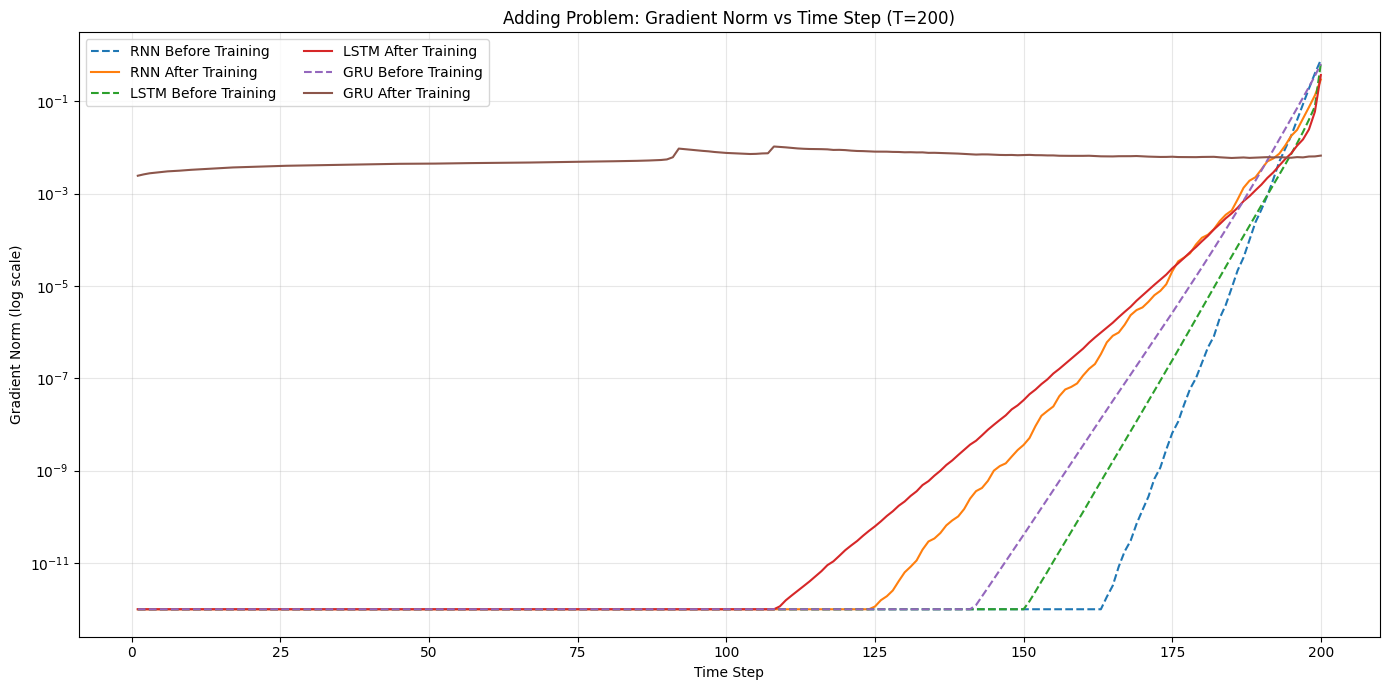

Gradient plot saved as Gradient_Norm_vs_Time_Step.png


In [85]:
plt.figure(figsize=(14, 7))

time_steps = np.arange(1, 201)

for model_name in ["RNN", "LSTM", "GRU"]:

    # Before training
    before = np.array(gradient_results[model_name]["before"])

    # After training
    after = np.array(gradient_results[model_name]["after"])

    # Avoid log(0) for plotting only
    before_plot = np.maximum(before, 1e-12)
    after_plot = np.maximum(after, 1e-12)

    plt.plot(
        time_steps,
        before_plot,
        linestyle="--",
        label=f"{model_name} Before Training"
    )

    plt.plot(
        time_steps,
        after_plot,
        linestyle="-",
        label=f"{model_name} After Training"
    )

plt.yscale("log")
plt.xlabel("Time Step")
plt.ylabel("Gradient Norm (log scale)")
plt.title("Adding Problem: Gradient Norm vs Time Step (T=200)")
plt.legend(ncol=2)
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.savefig(
    "Gradient_Norm_vs_Time_Step.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Gradient plot saved as Gradient_Norm_vs_Time_Step.png")

In [88]:
import copy
import time
import random
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

def train_model_sweep(
    model,
    seed,
    epochs=30,
    batch_size=64,
    lr=0.001,
    patience=5
):
    # Reproducibility
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

    model = model.to(device)

    # Training dataset and loader
    train_dataset = TensorDataset(
        X_train_tensor,
        y_train_tensor.long()
    )

    generator = torch.Generator()
    generator.manual_seed(seed)

    train_loader = DataLoader(
        train_dataset,
        batch_size=batch_size,
        shuffle=True,
        generator=generator
    )

    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)

    history = {
        "train_loss": [],
        "val_loss": [],
        "val_accuracy": [],
        "epoch_time": []
    }

    best_val_loss = float("inf")
    best_state = None
    best_epoch = 0
    epochs_without_improvement = 0

    for epoch in range(epochs):

        start_time = time.time()

        # Training
        model.train()
        running_loss = 0.0

        for inputs, targets in train_loader:

            inputs = inputs.to(device)
            targets = targets.to(device)

            optimizer.zero_grad()

            outputs = model(inputs)
            loss = criterion(outputs, targets)

            loss.backward()
            optimizer.step()

            running_loss += loss.item() * inputs.size(0)

        train_loss = running_loss / len(train_dataset)

        # Validation
        model.eval()

        val_loss_total = 0.0
        correct = 0
        total = 0

        with torch.no_grad():

            for start in range(0, len(X_val_tensor), batch_size):

                inputs = X_val_tensor[start:start + batch_size].to(device)
                targets = y_val_tensor[start:start + batch_size].to(device).long()

                outputs = model(inputs)
                loss = criterion(outputs, targets)

                val_loss_total += loss.item() * inputs.size(0)

                predictions = outputs.argmax(dim=1)

                correct += (predictions == targets).sum().item()
                total += targets.size(0)

        val_loss = val_loss_total / total
        val_accuracy = correct / total

        epoch_time = time.time() - start_time

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["val_accuracy"].append(val_accuracy)
        history["epoch_time"].append(epoch_time)

        # Save best validation checkpoint
        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_state = copy.deepcopy(model.state_dict())
            best_epoch = epoch + 1
            epochs_without_improvement = 0
        else:
            epochs_without_improvement += 1

        print(
            f"Epoch [{epoch+1:02d}/{epochs}] "
            f"Train Loss: {train_loss:.4f} | "
            f"Val Loss: {val_loss:.4f} | "
            f"Val Accuracy: {val_accuracy:.4f} | "
            f"Time: {epoch_time:.2f}s"
        )

        # Early stopping
        if epochs_without_improvement >= patience:
            print(f"Early stopping at epoch {epoch+1}.")
            break

    # Restore best checkpoint
    model.load_state_dict(best_state)

    history["best_epoch"] = best_epoch
    history["best_val_loss"] = best_val_loss

    return model, history

In [89]:
# Test LSTM with hidden size 16 and seed 42

test_lstm = LSTMClassifier(
    input_size=9,
    hidden_size=16,
    num_classes=6
)

test_lstm, test_lstm_history = train_model_sweep(
    model=test_lstm,
    seed=42,
    epochs=30,
    batch_size=64,
    lr=0.001,
    patience=5
)

print("\nTest completed.")
print("Best epoch:", test_lstm_history["best_epoch"])
print("Best validation loss:", test_lstm_history["best_val_loss"])
print("Total epochs trained:", len(test_lstm_history["train_loss"]))

Epoch [01/30] Train Loss: 1.6774 | Val Loss: 1.4587 | Val Accuracy: 0.5430 | Time: 15.67s
Epoch [02/30] Train Loss: 1.1947 | Val Loss: 0.9695 | Val Accuracy: 0.6208 | Time: 8.51s
Epoch [03/30] Train Loss: 0.8330 | Val Loss: 0.7652 | Val Accuracy: 0.7290 | Time: 7.78s
Epoch [04/30] Train Loss: 0.7118 | Val Loss: 0.7377 | Val Accuracy: 0.7235 | Time: 8.52s
Epoch [05/30] Train Loss: 0.7036 | Val Loss: 0.7443 | Val Accuracy: 0.6746 | Time: 8.56s
Epoch [06/30] Train Loss: 0.6863 | Val Loss: 0.7260 | Val Accuracy: 0.7029 | Time: 7.69s
Epoch [07/30] Train Loss: 0.6504 | Val Loss: 0.7298 | Val Accuracy: 0.7501 | Time: 8.56s
Epoch [08/30] Train Loss: 0.6023 | Val Loss: 0.6061 | Val Accuracy: 0.7685 | Time: 8.53s
Epoch [09/30] Train Loss: 0.5781 | Val Loss: 0.5109 | Val Accuracy: 0.8534 | Time: 7.74s
Epoch [10/30] Train Loss: 0.5047 | Val Loss: 0.4762 | Val Accuracy: 0.8556 | Time: 8.54s
Epoch [11/30] Train Loss: 0.4607 | Val Loss: 0.4380 | Val Accuracy: 0.8701 | Time: 8.61s
Epoch [12/30] Train 

In [92]:
for model_name in ["RNN", "LSTM", "GRU"]:
    for seed in [42, 123, 2026]:

        key = (model_name, seed, 100)

        if key in adding_all_results:
            result = adding_all_results[key]

            print(
                f"{model_name} | Seed {seed} | "
                f"Best validation loss: {result['best_val_loss']:.6f}"
            )
        else:
            print(f"MISSING: {key}")

RNN | Seed 42 | Best validation loss: 0.154311
RNN | Seed 123 | Best validation loss: 0.153828
RNN | Seed 2026 | Best validation loss: 0.160214
LSTM | Seed 42 | Best validation loss: 0.159615
LSTM | Seed 123 | Best validation loss: 0.159025
LSTM | Seed 2026 | Best validation loss: 0.159361
GRU | Seed 42 | Best validation loss: 0.002330
GRU | Seed 123 | Best validation loss: 0.002866
GRU | Seed 2026 | Best validation loss: 0.001581


In [96]:
X_add_test_100, y_add_test_100 = make_adding(
    n=1000,
    T=100,
    seed=2
)

# Convert to PyTorch tensors
X_add_test_100 = torch.tensor(
    X_add_test_100,
    dtype=torch.float32
)

y_add_test_100 = torch.tensor(
    y_add_test_100,
    dtype=torch.float32
).reshape(-1, 1)

print("Test input shape:", X_add_test_100.shape)
print("Test target shape:", y_add_test_100.shape)

Test input shape: torch.Size([1000, 100, 2])
Test target shape: torch.Size([1000, 1])


In [97]:
# Select one T=100 test sample
x_gradient_100 = X_add_test_100[0:1].to(device)
y_gradient_100 = y_add_test_100[0:1].to(device)

# Create fresh models (before training)
gradient_models_before_100 = {
    "RNN": RNNAdding(input_size=2, hidden_size=64).to(device),
    "LSTM": LSTMAdding(input_size=2, hidden_size=64).to(device),
    "GRU": GRUAdding(input_size=2, hidden_size=64).to(device)
}

# Retrieve trained models (after training), seed 42
gradient_models_after_100 = {
    model_name: adding_all_results[(model_name, 42, 100)]["model"]
    for model_name in ["RNN", "LSTM", "GRU"]
}

# Calculate hidden-state gradient norms
gradient_results_100 = {}

for model_name in ["RNN", "LSTM", "GRU"]:

    before_norms = calculate_hidden_gradient_norms(
        gradient_models_before_100[model_name],
        x_gradient_100,
        y_gradient_100,
        model_name
    )

    after_norms = calculate_hidden_gradient_norms(
        gradient_models_after_100[model_name],
        x_gradient_100,
        y_gradient_100,
        model_name
    )

    gradient_results_100[model_name] = {
        "before": before_norms,
        "after": after_norms
    }

    print(
        f"{model_name}: "
        f"Before = {len(before_norms)} steps, "
        f"After = {len(after_norms)} steps"
    )

RNN: Before = 100 steps, After = 100 steps
LSTM: Before = 100 steps, After = 100 steps
GRU: Before = 100 steps, After = 100 steps


Plot gradient norms at T=100

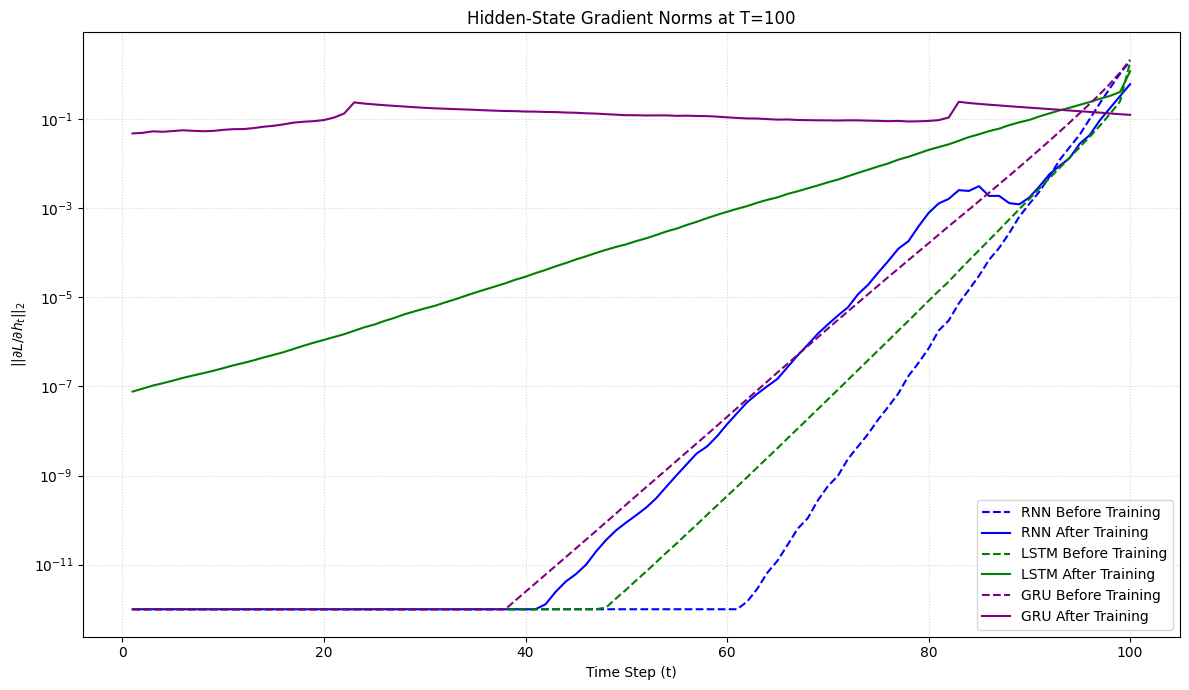

In [98]:
plt.figure(figsize=(12, 7))

colors = {
    "RNN": "blue",
    "LSTM": "green",
    "GRU": "purple"
}

time_steps = np.arange(1, 101)

for model_name in ["RNN", "LSTM", "GRU"]:

    before = np.array(
        gradient_results_100[model_name]["before"]
    )

    after = np.array(
        gradient_results_100[model_name]["after"]
    )

    # Clamp very small values for log-scale visualization
    before_plot = np.maximum(before, 1e-12)
    after_plot = np.maximum(after, 1e-12)

    plt.plot(
        time_steps,
        before_plot,
        linestyle="--",
        color=colors[model_name],
        label=f"{model_name} Before Training"
    )

    plt.plot(
        time_steps,
        after_plot,
        linestyle="-",
        color=colors[model_name],
        label=f"{model_name} After Training"
    )

plt.yscale("log")
plt.xlabel("Time Step (t)")
plt.ylabel(r"$||\partial L / \partial h_t||_2$")
plt.title("Hidden-State Gradient Norms at T=100")
plt.legend()
plt.grid(True, which="both", linestyle=":", alpha=0.5)
plt.tight_layout()

plt.savefig(
    "Gradient_Norm_vs_Time_Step_T100.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [99]:
from sklearn.metrics import accuracy_score, f1_score

test_lstm.eval()

all_predictions = []
all_targets = []

with torch.no_grad():
    for start in range(0, len(X_test_tensor), 64):

        inputs = X_test_tensor[start:start + 64].to(device)
        targets = y_test_tensor[start:start + 64].to(device).long()

        outputs = test_lstm(inputs)
        predictions = outputs.argmax(dim=1)

        all_predictions.extend(predictions.cpu().numpy())
        all_targets.extend(targets.cpu().numpy())

lstm16_accuracy = accuracy_score(all_targets, all_predictions)
lstm16_macro_f1 = f1_score(
    all_targets,
    all_predictions,
    average="macro"
)

print("LSTM | Hidden size 16 | Seed 42")
print("Test Accuracy:", round(lstm16_accuracy, 4))
print("Macro F1:", round(lstm16_macro_f1, 4))
print("Parameters:", sum(p.numel() for p in test_lstm.parameters()))
print("Best Epoch:", test_lstm_history["best_epoch"])
print("Best Validation Loss:", round(test_lstm_history["best_val_loss"], 6))

LSTM | Hidden size 16 | Seed 42
Test Accuracy: 0.8975
Macro F1: 0.8965
Parameters: 1830
Best Epoch: 27
Best Validation Loss: 0.230655


Prepare the full hidden-size sweep
We'll run 24 experiments:
- LSTM and GRU
- Hidden sizes: 16, 32, 64, 128
- Seeds: 42, 123, 2026

In [100]:
def set_experiment_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


# Set seed BEFORE creating the model
set_experiment_seed(42)

test_lstm = LSTMClassifier(
    input_size=9,
    hidden_size=16,
    num_classes=6
)

test_lstm, test_lstm_history = train_model_sweep(
    model=test_lstm,
    seed=42,
    epochs=30,
    batch_size=64,
    lr=0.001,
    patience=5
)

print("Best epoch:", test_lstm_history["best_epoch"])
print("Best validation loss:", test_lstm_history["best_val_loss"])

Epoch [01/30] Train Loss: 1.5734 | Val Loss: 1.4048 | Val Accuracy: 0.4053 | Time: 14.35s
Epoch [02/30] Train Loss: 1.2568 | Val Loss: 1.0876 | Val Accuracy: 0.6313 | Time: 7.79s
Epoch [03/30] Train Loss: 0.8719 | Val Loss: 0.7756 | Val Accuracy: 0.6952 | Time: 8.59s
Epoch [04/30] Train Loss: 0.7462 | Val Loss: 0.6925 | Val Accuracy: 0.7368 | Time: 8.58s
Epoch [05/30] Train Loss: 0.6764 | Val Loss: 0.6493 | Val Accuracy: 0.7624 | Time: 7.80s
Epoch [06/30] Train Loss: 0.6339 | Val Loss: 0.5880 | Val Accuracy: 0.7890 | Time: 8.72s
Epoch [07/30] Train Loss: 0.5972 | Val Loss: 0.5650 | Val Accuracy: 0.8107 | Time: 8.52s
Epoch [08/30] Train Loss: 0.5663 | Val Loss: 0.5079 | Val Accuracy: 0.8107 | Time: 7.80s
Epoch [09/30] Train Loss: 0.5067 | Val Loss: 0.4952 | Val Accuracy: 0.8329 | Time: 8.83s
Epoch [10/30] Train Loss: 0.4631 | Val Loss: 0.4604 | Val Accuracy: 0.8667 | Time: 8.67s
Epoch [11/30] Train Loss: 0.4264 | Val Loss: 0.3961 | Val Accuracy: 0.8806 | Time: 8.17s
Epoch [12/30] Train 

In [101]:
test_lstm.eval()

all_predictions = []
all_targets = []

with torch.no_grad():
    for start in range(0, len(X_test_tensor), 64):
        inputs = X_test_tensor[start:start+64].to(device)
        targets = y_test_tensor[start:start+64].to(device).long()

        outputs = test_lstm(inputs)
        predictions = outputs.argmax(dim=1)

        all_predictions.extend(predictions.cpu().numpy())
        all_targets.extend(targets.cpu().numpy())

lstm16_accuracy = accuracy_score(all_targets, all_predictions)
lstm16_macro_f1 = f1_score(
    all_targets, all_predictions, average="macro"
)

lstm16_parameters = sum(
    p.numel() for p in test_lstm.parameters()
)

hidden_sweep_results = {}

hidden_sweep_results[("LSTM", 16, 42)] = {
    "model": test_lstm,
    "history": test_lstm_history,
    "accuracy": lstm16_accuracy,
    "macro_f1": lstm16_macro_f1,
    "parameters": lstm16_parameters
}

print("Model: LSTM")
print("Hidden size: 16")
print("Seed: 42")
print(f"Test accuracy: {lstm16_accuracy:.4f}")
print(f"Macro F1: {lstm16_macro_f1:.4f}")
print(f"Parameters: {lstm16_parameters}")
print(f"Best epoch: {test_lstm_history['best_epoch']}")
print(f"Best validation loss: {test_lstm_history['best_val_loss']:.6f}")
print("Stored experiments:", len(hidden_sweep_results))

Model: LSTM
Hidden size: 16
Seed: 42
Test accuracy: 0.8955
Macro F1: 0.8956
Parameters: 1830
Best epoch: 27
Best validation loss: 0.142504
Stored experiments: 1


In [102]:
def set_experiment_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


# Set seed BEFORE creating the model
set_experiment_seed(42)

test_lstm = LSTMClassifier(
    input_size=9,
    hidden_size=16,
    num_classes=6
)

# Train using batch size 64
test_lstm, test_lstm_history = train_model_sweep(
    model=test_lstm,
    seed=42,
    epochs=30,
    batch_size=64,
    lr=0.001,
    patience=5
)

# Evaluate on the test set
test_lstm.eval()
all_predictions = []
all_targets = []

with torch.no_grad():
    for start in range(0, len(X_test_tensor), 64):
        inputs = X_test_tensor[start:start+64].to(device)
        targets = y_test_tensor[start:start+64].to(device).long()

        outputs = test_lstm(inputs)
        predictions = outputs.argmax(dim=1)

        all_predictions.extend(predictions.cpu().numpy())
        all_targets.extend(targets.cpu().numpy())

lstm16_accuracy = accuracy_score(all_targets, all_predictions)
lstm16_macro_f1 = f1_score(
    all_targets, all_predictions, average="macro"
)

lstm16_parameters = sum(
    p.numel() for p in test_lstm.parameters()
)

# Update the first experiment
hidden_sweep_results[("LSTM", 16, 42)] = {
    "model": test_lstm,
    "history": test_lstm_history,
    "accuracy": lstm16_accuracy,
    "macro_f1": lstm16_macro_f1,
    "parameters": lstm16_parameters
}

print("Reproducible experiment saved.")
print(f"Test accuracy: {lstm16_accuracy:.4f}")
print(f"Macro F1: {lstm16_macro_f1:.4f}")
print(f"Parameters: {lstm16_parameters}")
print(f"Best epoch: {test_lstm_history['best_epoch']}")
print(f"Best validation loss: {test_lstm_history['best_val_loss']:.6f}")
print("Stored experiments:", len(hidden_sweep_results))

Epoch [01/30] Train Loss: 1.5734 | Val Loss: 1.4048 | Val Accuracy: 0.4053 | Time: 15.99s
Epoch [02/30] Train Loss: 1.2568 | Val Loss: 1.0876 | Val Accuracy: 0.6313 | Time: 8.56s
Epoch [03/30] Train Loss: 0.8719 | Val Loss: 0.7756 | Val Accuracy: 0.6952 | Time: 8.53s
Epoch [04/30] Train Loss: 0.7462 | Val Loss: 0.6925 | Val Accuracy: 0.7368 | Time: 7.79s
Epoch [05/30] Train Loss: 0.6764 | Val Loss: 0.6493 | Val Accuracy: 0.7624 | Time: 8.60s
Epoch [06/30] Train Loss: 0.6339 | Val Loss: 0.5880 | Val Accuracy: 0.7890 | Time: 8.52s
Epoch [07/30] Train Loss: 0.5972 | Val Loss: 0.5650 | Val Accuracy: 0.8107 | Time: 8.73s
Epoch [08/30] Train Loss: 0.5663 | Val Loss: 0.5079 | Val Accuracy: 0.8107 | Time: 8.58s
Epoch [09/30] Train Loss: 0.5067 | Val Loss: 0.4952 | Val Accuracy: 0.8329 | Time: 8.59s
Epoch [10/30] Train Loss: 0.4631 | Val Loss: 0.4604 | Val Accuracy: 0.8667 | Time: 7.89s
Epoch [11/30] Train Loss: 0.4264 | Val Loss: 0.3961 | Val Accuracy: 0.8806 | Time: 8.59s
Epoch [12/30] Train 

In [103]:
set_experiment_seed(123)

model = LSTMClassifier(
    input_size=9,
    hidden_size=16,
    num_classes=6
)

model, history = train_model_sweep(
    model=model,
    seed=123,
    epochs=30,
    batch_size=64,
    lr=0.001,
    patience=5
)

model.eval()
predictions = []
targets_all = []

with torch.no_grad():
    for start in range(0, len(X_test_tensor), 64):
        inputs = X_test_tensor[start:start+64].to(device)
        targets = y_test_tensor[start:start+64].to(device).long()

        outputs = model(inputs)
        predictions.extend(outputs.argmax(dim=1).cpu().numpy())
        targets_all.extend(targets.cpu().numpy())

accuracy = accuracy_score(targets_all, predictions)
macro_f1 = f1_score(targets_all, predictions, average="macro")
parameters = sum(p.numel() for p in model.parameters())

hidden_sweep_results[("LSTM", 16, 123)] = {
    "model": model,
    "history": history,
    "accuracy": accuracy,
    "macro_f1": macro_f1,
    "parameters": parameters
}

print("Model: LSTM | Hidden size: 16 | Seed: 123")
print(f"Test accuracy: {accuracy:.4f}")
print(f"Macro F1: {macro_f1:.4f}")
print(f"Parameters: {parameters}")
print(f"Best epoch: {history['best_epoch']}")
print(f"Best validation loss: {history['best_val_loss']:.6f}")
print("Stored experiments:", len(hidden_sweep_results))

Epoch [01/30] Train Loss: 1.6931 | Val Loss: 1.5135 | Val Accuracy: 0.5297 | Time: 12.24s
Epoch [02/30] Train Loss: 1.1624 | Val Loss: 0.9423 | Val Accuracy: 0.6830 | Time: 8.29s
Epoch [03/30] Train Loss: 0.8647 | Val Loss: 0.8521 | Val Accuracy: 0.6807 | Time: 8.05s
Epoch [04/30] Train Loss: 0.7819 | Val Loss: 0.7923 | Val Accuracy: 0.7079 | Time: 8.60s
Epoch [05/30] Train Loss: 0.7220 | Val Loss: 0.7116 | Val Accuracy: 0.7252 | Time: 8.17s
Epoch [06/30] Train Loss: 0.6641 | Val Loss: 0.6240 | Val Accuracy: 0.7851 | Time: 8.08s
Epoch [07/30] Train Loss: 0.6040 | Val Loss: 0.5665 | Val Accuracy: 0.8023 | Time: 8.50s
Epoch [08/30] Train Loss: 0.5599 | Val Loss: 0.5434 | Val Accuracy: 0.8040 | Time: 8.00s
Epoch [09/30] Train Loss: 0.5125 | Val Loss: 0.4809 | Val Accuracy: 0.8351 | Time: 8.37s
Epoch [10/30] Train Loss: 0.4593 | Val Loss: 0.4403 | Val Accuracy: 0.8545 | Time: 8.54s
Epoch [11/30] Train Loss: 0.3916 | Val Loss: 0.3649 | Val Accuracy: 0.8912 | Time: 7.81s
Epoch [12/30] Train 

In [104]:
set_experiment_seed(2026)

model = LSTMClassifier(
    input_size=9,
    hidden_size=16,
    num_classes=6
)

model, history = train_model_sweep(
    model=model,
    seed=2026,
    epochs=30,
    batch_size=64,
    lr=0.001,
    patience=5
)

model.eval()
predictions = []
targets_all = []

with torch.no_grad():
    for start in range(0, len(X_test_tensor), 64):
        inputs = X_test_tensor[start:start+64].to(device)
        targets = y_test_tensor[start:start+64].to(device).long()

        outputs = model(inputs)
        predictions.extend(outputs.argmax(dim=1).cpu().numpy())
        targets_all.extend(targets.cpu().numpy())

accuracy = accuracy_score(targets_all, predictions)
macro_f1 = f1_score(targets_all, predictions, average="macro")
parameters = sum(p.numel() for p in model.parameters())

hidden_sweep_results[("LSTM", 16, 2026)] = {
    "model": model,
    "history": history,
    "accuracy": accuracy,
    "macro_f1": macro_f1,
    "parameters": parameters
}

print("Model: LSTM | Hidden size: 16 | Seed: 2026")
print(f"Test accuracy: {accuracy:.4f}")
print(f"Macro F1: {macro_f1:.4f}")
print(f"Parameters: {parameters}")
print(f"Best epoch: {history['best_epoch']}")
print(f"Best validation loss: {history['best_val_loss']:.6f}")
print("Stored experiments:", len(hidden_sweep_results))

Epoch [01/30] Train Loss: 1.6209 | Val Loss: 1.4320 | Val Accuracy: 0.4609 | Time: 16.82s
Epoch [02/30] Train Loss: 1.2478 | Val Loss: 1.0592 | Val Accuracy: 0.5602 | Time: 8.57s
Epoch [03/30] Train Loss: 0.9000 | Val Loss: 0.7702 | Val Accuracy: 0.7157 | Time: 8.35s
Epoch [04/30] Train Loss: 0.7008 | Val Loss: 0.6326 | Val Accuracy: 0.7596 | Time: 7.98s
Epoch [05/30] Train Loss: 0.5991 | Val Loss: 0.5377 | Val Accuracy: 0.8418 | Time: 8.47s
Epoch [06/30] Train Loss: 0.5118 | Val Loss: 0.4486 | Val Accuracy: 0.8956 | Time: 8.47s
Epoch [07/30] Train Loss: 0.4103 | Val Loss: 0.3811 | Val Accuracy: 0.9028 | Time: 8.02s
Epoch [08/30] Train Loss: 0.3740 | Val Loss: 0.4318 | Val Accuracy: 0.8462 | Time: 8.59s
Epoch [09/30] Train Loss: 0.3576 | Val Loss: 0.3184 | Val Accuracy: 0.9228 | Time: 8.19s
Epoch [10/30] Train Loss: 0.3035 | Val Loss: 0.3649 | Val Accuracy: 0.9001 | Time: 8.20s
Epoch [11/30] Train Loss: 0.2916 | Val Loss: 0.2822 | Val Accuracy: 0.9334 | Time: 8.57s
Epoch [12/30] Train 

In [105]:
set_experiment_seed(42)

model = LSTMClassifier(
    input_size=9,
    hidden_size=32,
    num_classes=6
)

model, history = train_model_sweep(
    model=model,
    seed=42,
    epochs=30,
    batch_size=64,
    lr=0.001,
    patience=5
)

model.eval()
predictions = []
targets_all = []

with torch.no_grad():
    for start in range(0, len(X_test_tensor), 64):
        inputs = X_test_tensor[start:start+64].to(device)
        targets = y_test_tensor[start:start+64].to(device).long()

        outputs = model(inputs)
        predictions.extend(outputs.argmax(dim=1).cpu().numpy())
        targets_all.extend(targets.cpu().numpy())

accuracy = accuracy_score(targets_all, predictions)
macro_f1 = f1_score(targets_all, predictions, average="macro")
parameters = sum(p.numel() for p in model.parameters())

hidden_sweep_results[("LSTM", 32, 42)] = {
    "model": model,
    "history": history,
    "accuracy": accuracy,
    "macro_f1": macro_f1,
    "parameters": parameters
}

print("Model: LSTM | Hidden size: 32 | Seed: 42")
print(f"Test accuracy: {accuracy:.4f}")
print(f"Macro F1: {macro_f1:.4f}")
print(f"Parameters: {parameters}")
print(f"Best epoch: {history['best_epoch']}")
print(f"Best validation loss: {history['best_val_loss']:.6f}")
print("Stored experiments:", len(hidden_sweep_results))

Epoch [01/30] Train Loss: 1.5413 | Val Loss: 1.2290 | Val Accuracy: 0.4125 | Time: 12.20s
Epoch [02/30] Train Loss: 0.9070 | Val Loss: 0.8287 | Val Accuracy: 0.6818 | Time: 8.52s
Epoch [03/30] Train Loss: 0.7151 | Val Loss: 0.6735 | Val Accuracy: 0.7146 | Time: 7.89s
Epoch [04/30] Train Loss: 0.6032 | Val Loss: 0.5710 | Val Accuracy: 0.7790 | Time: 8.66s
Epoch [05/30] Train Loss: 0.5003 | Val Loss: 0.4362 | Val Accuracy: 0.8323 | Time: 8.61s
Epoch [06/30] Train Loss: 0.3930 | Val Loss: 0.3459 | Val Accuracy: 0.8923 | Time: 7.78s
Epoch [07/30] Train Loss: 0.3202 | Val Loss: 0.3705 | Val Accuracy: 0.9145 | Time: 8.70s
Epoch [08/30] Train Loss: 0.3046 | Val Loss: 0.3005 | Val Accuracy: 0.9456 | Time: 8.59s
Epoch [09/30] Train Loss: 0.2909 | Val Loss: 0.2338 | Val Accuracy: 0.9484 | Time: 7.78s
Epoch [10/30] Train Loss: 0.2799 | Val Loss: 0.2811 | Val Accuracy: 0.9356 | Time: 8.58s
Epoch [11/30] Train Loss: 0.2249 | Val Loss: 0.1379 | Val Accuracy: 0.9783 | Time: 8.64s
Epoch [12/30] Train 

In [106]:
set_experiment_seed(123)

model = LSTMClassifier(
    input_size=9,
    hidden_size=32,
    num_classes=6
)

model, history = train_model_sweep(
    model=model,
    seed=123,
    epochs=30,
    batch_size=64,
    lr=0.001,
    patience=5
)

model.eval()
predictions = []
targets_all = []

with torch.no_grad():
    for start in range(0, len(X_test_tensor), 64):
        inputs = X_test_tensor[start:start+64].to(device)
        targets = y_test_tensor[start:start+64].to(device).long()

        outputs = model(inputs)
        predictions.extend(outputs.argmax(dim=1).cpu().numpy())
        targets_all.extend(targets.cpu().numpy())

accuracy = accuracy_score(targets_all, predictions)
macro_f1 = f1_score(targets_all, predictions, average="macro")
parameters = sum(p.numel() for p in model.parameters())

hidden_sweep_results[("LSTM", 32, 123)] = {
    "model": model,
    "history": history,
    "accuracy": accuracy,
    "macro_f1": macro_f1,
    "parameters": parameters
}

print("Model: LSTM | Hidden size: 32 | Seed: 123")
print(f"Test accuracy: {accuracy:.4f}")
print(f"Macro F1: {macro_f1:.4f}")
print(f"Parameters: {parameters}")
print(f"Best epoch: {history['best_epoch']}")
print(f"Best validation loss: {history['best_val_loss']:.6f}")
print("Stored experiments:", len(hidden_sweep_results))

Epoch [01/30] Train Loss: 1.5146 | Val Loss: 1.1827 | Val Accuracy: 0.4675 | Time: 15.85s
Epoch [02/30] Train Loss: 0.8644 | Val Loss: 0.8410 | Val Accuracy: 0.6563 | Time: 8.40s
Epoch [03/30] Train Loss: 0.7042 | Val Loss: 0.6632 | Val Accuracy: 0.7601 | Time: 8.58s
Epoch [04/30] Train Loss: 0.5948 | Val Loss: 0.5043 | Val Accuracy: 0.8456 | Time: 7.88s
Epoch [05/30] Train Loss: 0.4424 | Val Loss: 0.7902 | Val Accuracy: 0.7324 | Time: 8.71s
Epoch [06/30] Train Loss: 0.5556 | Val Loss: 0.4347 | Val Accuracy: 0.8640 | Time: 8.55s
Epoch [07/30] Train Loss: 0.4426 | Val Loss: 0.3921 | Val Accuracy: 0.8812 | Time: 7.82s
Epoch [08/30] Train Loss: 0.3281 | Val Loss: 0.3220 | Val Accuracy: 0.9084 | Time: 8.85s
Epoch [09/30] Train Loss: 0.2743 | Val Loss: 0.3134 | Val Accuracy: 0.9184 | Time: 9.66s
Epoch [10/30] Train Loss: 0.2463 | Val Loss: 0.2255 | Val Accuracy: 0.9539 | Time: 8.32s
Epoch [11/30] Train Loss: 0.2261 | Val Loss: 0.2290 | Val Accuracy: 0.9534 | Time: 8.42s
Epoch [12/30] Train 

In [107]:
set_experiment_seed(2026)

model = LSTMClassifier(
    input_size=9,
    hidden_size=32,
    num_classes=6
)

model, history = train_model_sweep(
    model=model,
    seed=2026,
    epochs=30,
    batch_size=64,
    lr=0.001,
    patience=5
)

model.eval()
predictions = []
targets_all = []

with torch.no_grad():
    for start in range(0, len(X_test_tensor), 64):
        inputs = X_test_tensor[start:start+64].to(device)
        targets = y_test_tensor[start:start+64].to(device).long()

        outputs = model(inputs)
        predictions.extend(outputs.argmax(dim=1).cpu().numpy())
        targets_all.extend(targets.cpu().numpy())

accuracy = accuracy_score(targets_all, predictions)
macro_f1 = f1_score(targets_all, predictions, average="macro")
parameters = sum(p.numel() for p in model.parameters())

hidden_sweep_results[("LSTM", 32, 2026)] = {
    "model": model,
    "history": history,
    "accuracy": accuracy,
    "macro_f1": macro_f1,
    "parameters": parameters
}

print("Model: LSTM | Hidden size: 32 | Seed: 2026")
print(f"Test accuracy: {accuracy:.4f}")
print(f"Macro F1: {macro_f1:.4f}")
print(f"Parameters: {parameters}")
print(f"Best epoch: {history['best_epoch']}")
print(f"Best validation loss: {history['best_val_loss']:.6f}")
print("Stored experiments:", len(hidden_sweep_results))

Epoch [01/30] Train Loss: 1.6053 | Val Loss: 1.3077 | Val Accuracy: 0.4431 | Time: 17.13s
Epoch [02/30] Train Loss: 0.9061 | Val Loss: 0.7557 | Val Accuracy: 0.7113 | Time: 9.01s
Epoch [03/30] Train Loss: 0.6425 | Val Loss: 0.5652 | Val Accuracy: 0.8068 | Time: 8.16s
Epoch [04/30] Train Loss: 0.4906 | Val Loss: 0.4405 | Val Accuracy: 0.8423 | Time: 8.37s
Epoch [05/30] Train Loss: 0.3920 | Val Loss: 0.3772 | Val Accuracy: 0.9067 | Time: 8.66s
Epoch [06/30] Train Loss: 0.3603 | Val Loss: 0.2996 | Val Accuracy: 0.9273 | Time: 8.19s
Epoch [07/30] Train Loss: 0.3261 | Val Loss: 0.2692 | Val Accuracy: 0.9500 | Time: 8.68s
Epoch [08/30] Train Loss: 0.2928 | Val Loss: 0.2922 | Val Accuracy: 0.9417 | Time: 8.89s
Epoch [09/30] Train Loss: 0.2562 | Val Loss: 0.3566 | Val Accuracy: 0.9267 | Time: 8.27s
Epoch [10/30] Train Loss: 0.3040 | Val Loss: 0.3417 | Val Accuracy: 0.9162 | Time: 8.25s
Epoch [11/30] Train Loss: 0.2600 | Val Loss: 0.2909 | Val Accuracy: 0.9034 | Time: 8.68s
Epoch [12/30] Train 

In [108]:
set_experiment_seed(42)

model = LSTMClassifier(
    input_size=9,
    hidden_size=64,
    num_classes=6
)

model, history = train_model_sweep(
    model=model,
    seed=42,
    epochs=30,
    batch_size=64,
    lr=0.001,
    patience=5
)

model.eval()
predictions = []
targets_all = []

with torch.no_grad():
    for start in range(0, len(X_test_tensor), 64):
        inputs = X_test_tensor[start:start+64].to(device)
        targets = y_test_tensor[start:start+64].to(device).long()

        outputs = model(inputs)
        predictions.extend(outputs.argmax(dim=1).cpu().numpy())
        targets_all.extend(targets.cpu().numpy())

accuracy = accuracy_score(targets_all, predictions)
macro_f1 = f1_score(targets_all, predictions, average="macro")
parameters = sum(p.numel() for p in model.parameters())

hidden_sweep_results[("LSTM", 64, 42)] = {
    "model": model,
    "history": history,
    "accuracy": accuracy,
    "macro_f1": macro_f1,
    "parameters": parameters
}

print("Model: LSTM | Hidden size: 64 | Seed: 42")
print(f"Test accuracy: {accuracy:.4f}")
print(f"Macro F1: {macro_f1:.4f}")
print(f"Parameters: {parameters}")
print(f"Best epoch: {history['best_epoch']}")
print(f"Best validation loss: {history['best_val_loss']:.6f}")
print("Stored experiments:", len(hidden_sweep_results))

Epoch [01/30] Train Loss: 1.3743 | Val Loss: 0.9911 | Val Accuracy: 0.6830 | Time: 12.55s
Epoch [02/30] Train Loss: 0.7294 | Val Loss: 0.6988 | Val Accuracy: 0.7857 | Time: 8.57s
Epoch [03/30] Train Loss: 0.4432 | Val Loss: 0.4965 | Val Accuracy: 0.8340 | Time: 11.10s
Epoch [04/30] Train Loss: 0.3421 | Val Loss: 0.3026 | Val Accuracy: 0.9234 | Time: 8.14s
Epoch [05/30] Train Loss: 0.2394 | Val Loss: 0.3678 | Val Accuracy: 0.8890 | Time: 8.93s
Epoch [06/30] Train Loss: 0.2282 | Val Loss: 0.1847 | Val Accuracy: 0.9522 | Time: 9.09s
Epoch [07/30] Train Loss: 0.1909 | Val Loss: 0.4675 | Val Accuracy: 0.8717 | Time: 8.36s
Epoch [08/30] Train Loss: 0.2149 | Val Loss: 0.1646 | Val Accuracy: 0.9650 | Time: 8.89s
Epoch [09/30] Train Loss: 0.1891 | Val Loss: 0.2982 | Val Accuracy: 0.9234 | Time: 9.03s
Epoch [10/30] Train Loss: 0.2421 | Val Loss: 0.1949 | Val Accuracy: 0.9600 | Time: 9.12s
Epoch [11/30] Train Loss: 0.1794 | Val Loss: 0.2382 | Val Accuracy: 0.9356 | Time: 8.99s
Epoch [12/30] Train

In [109]:
set_experiment_seed(123)

model = LSTMClassifier(
    input_size=9,
    hidden_size=64,
    num_classes=6
)

model, history = train_model_sweep(
    model=model,
    seed=123,
    epochs=30,
    batch_size=64,
    lr=0.001,
    patience=5
)

model.eval()
predictions = []
targets_all = []

with torch.no_grad():
    for start in range(0, len(X_test_tensor), 64):
        inputs = X_test_tensor[start:start+64].to(device)
        targets = y_test_tensor[start:start+64].to(device).long()

        outputs = model(inputs)
        predictions.extend(outputs.argmax(dim=1).cpu().numpy())
        targets_all.extend(targets.cpu().numpy())

accuracy = accuracy_score(targets_all, predictions)
macro_f1 = f1_score(targets_all, predictions, average="macro")
parameters = sum(p.numel() for p in model.parameters())

hidden_sweep_results[("LSTM", 64, 123)] = {
    "model": model,
    "history": history,
    "accuracy": accuracy,
    "macro_f1": macro_f1,
    "parameters": parameters
}

print("Model: LSTM | Hidden size: 64 | Seed: 123")
print(f"Test accuracy: {accuracy:.4f}")
print(f"Macro F1: {macro_f1:.4f}")
print(f"Parameters: {parameters}")
print(f"Best epoch: {history['best_epoch']}")
print(f"Best validation loss: {history['best_val_loss']:.6f}")
print("Stored experiments:", len(hidden_sweep_results))


Epoch [01/30] Train Loss: 1.3489 | Val Loss: 0.9061 | Val Accuracy: 0.6607 | Time: 16.43s
Epoch [02/30] Train Loss: 0.7773 | Val Loss: 0.6712 | Val Accuracy: 0.7557 | Time: 8.67s
Epoch [03/30] Train Loss: 0.5493 | Val Loss: 0.4693 | Val Accuracy: 0.8018 | Time: 8.59s
Epoch [04/30] Train Loss: 0.7956 | Val Loss: 0.5878 | Val Accuracy: 0.8096 | Time: 7.81s
Epoch [05/30] Train Loss: 0.4794 | Val Loss: 0.3620 | Val Accuracy: 0.8534 | Time: 8.71s
Epoch [06/30] Train Loss: 0.3513 | Val Loss: 0.3458 | Val Accuracy: 0.8534 | Time: 8.55s
Epoch [07/30] Train Loss: 0.2995 | Val Loss: 0.2569 | Val Accuracy: 0.9173 | Time: 7.80s
Epoch [08/30] Train Loss: 0.2959 | Val Loss: 0.2747 | Val Accuracy: 0.9167 | Time: 8.62s
Epoch [09/30] Train Loss: 0.3621 | Val Loss: 0.4602 | Val Accuracy: 0.8018 | Time: 8.45s
Epoch [10/30] Train Loss: 0.3307 | Val Loss: 0.2111 | Val Accuracy: 0.9484 | Time: 7.99s
Epoch [11/30] Train Loss: 0.2313 | Val Loss: 0.2799 | Val Accuracy: 0.9361 | Time: 8.62s
Epoch [12/30] Train 

In [110]:
set_experiment_seed(2026)

model = LSTMClassifier(
    input_size=9,
    hidden_size=64,
    num_classes=6
)

model, history = train_model_sweep(
    model=model,
    seed=2026,
    epochs=30,
    batch_size=64,
    lr=0.001,
    patience=5
)

model.eval()
predictions = []
targets_all = []

with torch.no_grad():
    for start in range(0, len(X_test_tensor), 64):
        inputs = X_test_tensor[start:start+64].to(device)
        targets = y_test_tensor[start:start+64].to(device).long()

        outputs = model(inputs)
        predictions.extend(outputs.argmax(dim=1).cpu().numpy())
        targets_all.extend(targets.cpu().numpy())

accuracy = accuracy_score(targets_all, predictions)
macro_f1 = f1_score(targets_all, predictions, average="macro")
parameters = sum(p.numel() for p in model.parameters())

hidden_sweep_results[("LSTM", 64, 2026)] = {
    "model": model,
    "history": history,
    "accuracy": accuracy,
    "macro_f1": macro_f1,
    "parameters": parameters
}

print("Model: LSTM | Hidden size: 64 | Seed: 2026")
print(f"Test accuracy: {accuracy:.4f}")
print(f"Macro F1: {macro_f1:.4f}")
print(f"Parameters: {parameters}")
print(f"Best epoch: {history['best_epoch']}")
print(f"Best validation loss: {history['best_val_loss']:.6f}")
print("Stored experiments:", len(hidden_sweep_results))

Epoch [01/30] Train Loss: 1.3957 | Val Loss: 1.0392 | Val Accuracy: 0.6557 | Time: 12.27s
Epoch [02/30] Train Loss: 0.8040 | Val Loss: 0.6372 | Val Accuracy: 0.7540 | Time: 10.92s
Epoch [03/30] Train Loss: 0.5778 | Val Loss: 0.5042 | Val Accuracy: 0.7735 | Time: 9.43s
Epoch [04/30] Train Loss: 0.4588 | Val Loss: 0.3659 | Val Accuracy: 0.8645 | Time: 7.89s
Epoch [05/30] Train Loss: 0.4005 | Val Loss: 0.3495 | Val Accuracy: 0.8834 | Time: 8.71s
Epoch [06/30] Train Loss: 0.3006 | Val Loss: 0.2205 | Val Accuracy: 0.9500 | Time: 8.59s
Epoch [07/30] Train Loss: 0.2195 | Val Loss: 0.2581 | Val Accuracy: 0.9273 | Time: 7.82s
Epoch [08/30] Train Loss: 0.1956 | Val Loss: 0.1569 | Val Accuracy: 0.9684 | Time: 8.63s
Epoch [09/30] Train Loss: 0.1720 | Val Loss: 0.1356 | Val Accuracy: 0.9789 | Time: 9.58s
Epoch [10/30] Train Loss: 0.1617 | Val Loss: 0.2662 | Val Accuracy: 0.9317 | Time: 7.75s
Epoch [11/30] Train Loss: 0.1993 | Val Loss: 0.1272 | Val Accuracy: 0.9839 | Time: 8.59s
Epoch [12/30] Train

In [111]:
set_experiment_seed(42)

model = LSTMClassifier(
    input_size=9,
    hidden_size=128,
    num_classes=6
)

model, history = train_model_sweep(
    model=model,
    seed=42,
    epochs=30,
    batch_size=64,
    lr=0.001,
    patience=5
)

model.eval()
predictions = []
targets_all = []

with torch.no_grad():
    for start in range(0, len(X_test_tensor), 64):
        inputs = X_test_tensor[start:start+64].to(device)
        targets = y_test_tensor[start:start+64].to(device).long()

        outputs = model(inputs)
        predictions.extend(outputs.argmax(dim=1).cpu().numpy())
        targets_all.extend(targets.cpu().numpy())

accuracy = accuracy_score(targets_all, predictions)
macro_f1 = f1_score(targets_all, predictions, average="macro")
parameters = sum(p.numel() for p in model.parameters())

hidden_sweep_results[("LSTM", 128, 42)] = {
    "model": model,
    "history": history,
    "accuracy": accuracy,
    "macro_f1": macro_f1,
    "parameters": parameters
}

print("Model: LSTM | Hidden size: 128 | Seed: 42")
print(f"Test accuracy: {accuracy:.4f}")
print(f"Macro F1: {macro_f1:.4f}")
print(f"Parameters: {parameters}")
print(f"Best epoch: {history['best_epoch']}")
print(f"Best validation loss: {history['best_val_loss']:.6f}")
print("Stored experiments:", len(hidden_sweep_results))

Epoch [01/30] Train Loss: 1.2342 | Val Loss: 0.9259 | Val Accuracy: 0.6469 | Time: 13.13s
Epoch [02/30] Train Loss: 0.8000 | Val Loss: 0.6464 | Val Accuracy: 0.6674 | Time: 8.66s
Epoch [03/30] Train Loss: 0.5554 | Val Loss: 0.6491 | Val Accuracy: 0.7735 | Time: 7.98s
Epoch [04/30] Train Loss: 0.5421 | Val Loss: 0.7008 | Val Accuracy: 0.7479 | Time: 8.75s
Epoch [05/30] Train Loss: 0.3897 | Val Loss: 0.3548 | Val Accuracy: 0.8795 | Time: 8.77s
Epoch [06/30] Train Loss: 0.2370 | Val Loss: 0.1754 | Val Accuracy: 0.9617 | Time: 7.94s
Epoch [07/30] Train Loss: 0.2623 | Val Loss: 0.2637 | Val Accuracy: 0.9417 | Time: 8.74s
Epoch [08/30] Train Loss: 0.2087 | Val Loss: 0.1874 | Val Accuracy: 0.9517 | Time: 13.04s
Epoch [09/30] Train Loss: 0.1709 | Val Loss: 0.1294 | Val Accuracy: 0.9761 | Time: 8.73s
Epoch [10/30] Train Loss: 0.2115 | Val Loss: 0.1127 | Val Accuracy: 0.9789 | Time: 8.07s
Epoch [11/30] Train Loss: 0.2157 | Val Loss: 0.1222 | Val Accuracy: 0.9700 | Time: 9.06s
Epoch [12/30] Train

In [112]:
set_experiment_seed(123)

model = LSTMClassifier(
    input_size=9,
    hidden_size=128,
    num_classes=6
)

model, history = train_model_sweep(
    model=model,
    seed=123,
    epochs=30,
    batch_size=64,
    lr=0.001,
    patience=5
)

model.eval()
predictions = []
targets_all = []

with torch.no_grad():
    for start in range(0, len(X_test_tensor), 64):
        inputs = X_test_tensor[start:start+64].to(device)
        targets = y_test_tensor[start:start+64].to(device).long()

        outputs = model(inputs)
        predictions.extend(outputs.argmax(dim=1).cpu().numpy())
        targets_all.extend(targets.cpu().numpy())

accuracy = accuracy_score(targets_all, predictions)
macro_f1 = f1_score(targets_all, predictions, average="macro")
parameters = sum(p.numel() for p in model.parameters())

hidden_sweep_results[("LSTM", 128, 123)] = {
    "model": model,
    "history": history,
    "accuracy": accuracy,
    "macro_f1": macro_f1,
    "parameters": parameters
}

print("Model: LSTM | Hidden size: 128 | Seed: 123")
print(f"Test accuracy: {accuracy:.4f}")
print(f"Macro F1: {macro_f1:.4f}")
print(f"Parameters: {parameters}")
print(f"Best epoch: {history['best_epoch']}")
print(f"Best validation loss: {history['best_val_loss']:.6f}")
print("Stored experiments:", len(hidden_sweep_results))

Epoch [01/30] Train Loss: 1.2348 | Val Loss: 0.9154 | Val Accuracy: 0.6280 | Time: 15.78s
Epoch [02/30] Train Loss: 0.7449 | Val Loss: 0.5677 | Val Accuracy: 0.7607 | Time: 8.77s
Epoch [03/30] Train Loss: 0.5854 | Val Loss: 0.5364 | Val Accuracy: 0.7640 | Time: 8.07s
Epoch [04/30] Train Loss: 0.4051 | Val Loss: 0.3897 | Val Accuracy: 0.9212 | Time: 8.94s
Epoch [05/30] Train Loss: 0.3520 | Val Loss: 0.3591 | Val Accuracy: 0.9278 | Time: 8.84s
Epoch [06/30] Train Loss: 0.3699 | Val Loss: 0.2544 | Val Accuracy: 0.9506 | Time: 7.98s
Epoch [07/30] Train Loss: 0.2513 | Val Loss: 0.1670 | Val Accuracy: 0.9650 | Time: 8.85s
Epoch [08/30] Train Loss: 0.2242 | Val Loss: 0.1993 | Val Accuracy: 0.9550 | Time: 8.78s
Epoch [09/30] Train Loss: 0.1840 | Val Loss: 0.1626 | Val Accuracy: 0.9661 | Time: 9.07s
Epoch [10/30] Train Loss: 0.1861 | Val Loss: 0.1013 | Val Accuracy: 0.9778 | Time: 8.78s
Epoch [11/30] Train Loss: 0.1598 | Val Loss: 0.1054 | Val Accuracy: 0.9783 | Time: 8.84s
Epoch [12/30] Train 

In [113]:
set_experiment_seed(2026)

model = LSTMClassifier(
    input_size=9,
    hidden_size=128,
    num_classes=6
)

model, history = train_model_sweep(
    model=model,
    seed=2026,
    epochs=30,
    batch_size=64,
    lr=0.001,
    patience=5
)

model.eval()
predictions = []
targets_all = []

with torch.no_grad():
    for start in range(0, len(X_test_tensor), 64):
        inputs = X_test_tensor[start:start+64].to(device)
        targets = y_test_tensor[start:start+64].to(device).long()

        outputs = model(inputs)
        predictions.extend(outputs.argmax(dim=1).cpu().numpy())
        targets_all.extend(targets.cpu().numpy())

accuracy = accuracy_score(targets_all, predictions)
macro_f1 = f1_score(targets_all, predictions, average="macro")
parameters = sum(p.numel() for p in model.parameters())

hidden_sweep_results[("LSTM", 128, 2026)] = {
    "model": model,
    "history": history,
    "accuracy": accuracy,
    "macro_f1": macro_f1,
    "parameters": parameters
}

print("Model: LSTM | Hidden size: 128 | Seed: 2026")
print(f"Test accuracy: {accuracy:.4f}")
print(f"Macro F1: {macro_f1:.4f}")
print(f"Parameters: {parameters}")
print(f"Best epoch: {history['best_epoch']}")
print(f"Best validation loss: {history['best_val_loss']:.6f}")
print("Stored experiments:", len(hidden_sweep_results))

Epoch [01/30] Train Loss: 1.2252 | Val Loss: 0.7757 | Val Accuracy: 0.7035 | Time: 17.37s
Epoch [02/30] Train Loss: 0.6341 | Val Loss: 0.5638 | Val Accuracy: 0.8007 | Time: 8.82s
Epoch [03/30] Train Loss: 0.5384 | Val Loss: 0.4554 | Val Accuracy: 0.8534 | Time: 8.84s
Epoch [04/30] Train Loss: 0.4365 | Val Loss: 0.4957 | Val Accuracy: 0.7796 | Time: 8.02s
Epoch [05/30] Train Loss: 0.2929 | Val Loss: 0.2733 | Val Accuracy: 0.9106 | Time: 8.78s
Epoch [06/30] Train Loss: 0.4049 | Val Loss: 0.3389 | Val Accuracy: 0.9228 | Time: 8.76s
Epoch [07/30] Train Loss: 0.2720 | Val Loss: 0.2348 | Val Accuracy: 0.9389 | Time: 7.91s
Epoch [08/30] Train Loss: 0.2220 | Val Loss: 0.1527 | Val Accuracy: 0.9695 | Time: 8.78s
Epoch [09/30] Train Loss: 0.3630 | Val Loss: 0.2663 | Val Accuracy: 0.9578 | Time: 8.99s
Epoch [10/30] Train Loss: 0.2239 | Val Loss: 0.0995 | Val Accuracy: 0.9828 | Time: 7.99s
Epoch [11/30] Train Loss: 0.1807 | Val Loss: 0.0740 | Val Accuracy: 0.9939 | Time: 8.79s
Epoch [12/30] Train 

GRU, hidden size 16, seed 42

In [114]:
set_experiment_seed(42)

model = GRUClassifier(
    input_size=9,
    hidden_size=16,
    num_classes=6
)

model, history = train_model_sweep(
    model=model,
    seed=42,
    epochs=30,
    batch_size=64,
    lr=0.001,
    patience=5
)

model.eval()
predictions = []
targets_all = []

with torch.no_grad():
    for start in range(0, len(X_test_tensor), 64):
        inputs = X_test_tensor[start:start+64].to(device)
        targets = y_test_tensor[start:start+64].to(device).long()

        outputs = model(inputs)
        predictions.extend(outputs.argmax(dim=1).cpu().numpy())
        targets_all.extend(targets.cpu().numpy())

accuracy = accuracy_score(targets_all, predictions)
macro_f1 = f1_score(targets_all, predictions, average="macro")
parameters = sum(p.numel() for p in model.parameters())

hidden_sweep_results[("GRU", 16, 42)] = {
    "model": model,
    "history": history,
    "accuracy": accuracy,
    "macro_f1": macro_f1,
    "parameters": parameters
}

print("Model: GRU | Hidden size: 16 | Seed: 42")
print(f"Test accuracy: {accuracy:.4f}")
print(f"Macro F1: {macro_f1:.4f}")
print(f"Parameters: {parameters}")
print(f"Best epoch: {history['best_epoch']}")
print(f"Best validation loss: {history['best_val_loss']:.6f}")
print("Stored experiments:", len(hidden_sweep_results))

Epoch [01/30] Train Loss: 1.5802 | Val Loss: 1.3968 | Val Accuracy: 0.4620 | Time: 18.51s
Epoch [02/30] Train Loss: 1.2464 | Val Loss: 1.0825 | Val Accuracy: 0.6047 | Time: 15.10s
Epoch [03/30] Train Loss: 0.8733 | Val Loss: 0.7483 | Val Accuracy: 0.7463 | Time: 15.46s
Epoch [04/30] Train Loss: 0.6353 | Val Loss: 0.6961 | Val Accuracy: 0.8062 | Time: 14.98s
Epoch [05/30] Train Loss: 0.5268 | Val Loss: 0.5551 | Val Accuracy: 0.8362 | Time: 14.84s
Epoch [06/30] Train Loss: 0.4524 | Val Loss: 0.5057 | Val Accuracy: 0.8562 | Time: 14.82s
Epoch [07/30] Train Loss: 0.4186 | Val Loss: 0.4717 | Val Accuracy: 0.8601 | Time: 14.75s
Epoch [08/30] Train Loss: 0.3758 | Val Loss: 0.4516 | Val Accuracy: 0.8606 | Time: 15.42s
Epoch [09/30] Train Loss: 0.3406 | Val Loss: 0.3424 | Val Accuracy: 0.8917 | Time: 14.94s
Epoch [10/30] Train Loss: 0.2922 | Val Loss: 0.3353 | Val Accuracy: 0.9062 | Time: 14.84s
Epoch [11/30] Train Loss: 0.2665 | Val Loss: 0.3269 | Val Accuracy: 0.9012 | Time: 14.77s
Epoch [12/

In [115]:
set_experiment_seed(123)

model = GRUClassifier(
    input_size=9,
    hidden_size=16,
    num_classes=6
)

model, history = train_model_sweep(
    model=model,
    seed=123,
    epochs=30,
    batch_size=64,
    lr=0.001,
    patience=5
)

model.eval()
predictions = []
targets_all = []

with torch.no_grad():
    for start in range(0, len(X_test_tensor), 64):
        inputs = X_test_tensor[start:start+64].to(device)
        targets = y_test_tensor[start:start+64].to(device).long()

        outputs = model(inputs)
        predictions.extend(outputs.argmax(dim=1).cpu().numpy())
        targets_all.extend(targets.cpu().numpy())

accuracy = accuracy_score(targets_all, predictions)
macro_f1 = f1_score(targets_all, predictions, average="macro")
parameters = sum(p.numel() for p in model.parameters())

hidden_sweep_results[("GRU", 16, 123)] = {
    "model": model,
    "history": history,
    "accuracy": accuracy,
    "macro_f1": macro_f1,
    "parameters": parameters
}

print("Model: GRU | Hidden size: 16 | Seed: 123")
print(f"Test accuracy: {accuracy:.4f}")
print(f"Macro F1: {macro_f1:.4f}")
print(f"Parameters: {parameters}")
print(f"Best epoch: {history['best_epoch']}")
print(f"Best validation loss: {history['best_val_loss']:.6f}")
print("Stored experiments:", len(hidden_sweep_results))

Epoch [01/30] Train Loss: 1.6987 | Val Loss: 1.5048 | Val Accuracy: 0.4020 | Time: 20.67s
Epoch [02/30] Train Loss: 1.2722 | Val Loss: 1.0675 | Val Accuracy: 0.6363 | Time: 17.83s
Epoch [03/30] Train Loss: 0.8219 | Val Loss: 0.7252 | Val Accuracy: 0.7274 | Time: 14.69s
Epoch [04/30] Train Loss: 0.6615 | Val Loss: 0.6382 | Val Accuracy: 0.8012 | Time: 14.85s
Epoch [05/30] Train Loss: 0.5735 | Val Loss: 0.5498 | Val Accuracy: 0.8273 | Time: 16.65s
Epoch [06/30] Train Loss: 0.4700 | Val Loss: 0.3996 | Val Accuracy: 0.8823 | Time: 15.01s
Epoch [07/30] Train Loss: 0.3577 | Val Loss: 0.3229 | Val Accuracy: 0.9189 | Time: 14.95s
Epoch [08/30] Train Loss: 0.2756 | Val Loss: 0.2429 | Val Accuracy: 0.9450 | Time: 14.97s
Epoch [09/30] Train Loss: 0.2256 | Val Loss: 0.2053 | Val Accuracy: 0.9511 | Time: 14.99s
Epoch [10/30] Train Loss: 0.1949 | Val Loss: 0.1805 | Val Accuracy: 0.9572 | Time: 15.22s
Epoch [11/30] Train Loss: 0.1820 | Val Loss: 0.1988 | Val Accuracy: 0.9489 | Time: 15.38s
Epoch [12/

In [116]:
set_experiment_seed(2026)

model = GRUClassifier(
    input_size=9,
    hidden_size=16,
    num_classes=6
)

model, history = train_model_sweep(
    model=model,
    seed=2026,
    epochs=30,
    batch_size=64,
    lr=0.001,
    patience=5
)

model.eval()
predictions = []
targets_all = []

with torch.no_grad():
    for start in range(0, len(X_test_tensor), 64):
        inputs = X_test_tensor[start:start+64].to(device)
        targets = y_test_tensor[start:start+64].to(device).long()

        outputs = model(inputs)
        predictions.extend(outputs.argmax(dim=1).cpu().numpy())
        targets_all.extend(targets.cpu().numpy())

accuracy = accuracy_score(targets_all, predictions)
macro_f1 = f1_score(targets_all, predictions, average="macro")
parameters = sum(p.numel() for p in model.parameters())

hidden_sweep_results[("GRU", 16, 2026)] = {
    "model": model,
    "history": history,
    "accuracy": accuracy,
    "macro_f1": macro_f1,
    "parameters": parameters
}

print("Model: GRU | Hidden size: 16 | Seed: 2026")
print(f"Test accuracy: {accuracy:.4f}")
print(f"Macro F1: {macro_f1:.4f}")
print(f"Parameters: {parameters}")
print(f"Best epoch: {history['best_epoch']}")
print(f"Best validation loss: {history['best_val_loss']:.6f}")
print("Stored experiments:", len(hidden_sweep_results))


Epoch [01/30] Train Loss: 1.6450 | Val Loss: 1.4406 | Val Accuracy: 0.4597 | Time: 24.30s
Epoch [02/30] Train Loss: 1.2764 | Val Loss: 1.1369 | Val Accuracy: 0.5269 | Time: 15.19s
Epoch [03/30] Train Loss: 0.8927 | Val Loss: 0.7075 | Val Accuracy: 0.7529 | Time: 15.05s
Epoch [04/30] Train Loss: 0.6357 | Val Loss: 0.5640 | Val Accuracy: 0.8157 | Time: 14.91s
Epoch [05/30] Train Loss: 0.5214 | Val Loss: 0.4793 | Val Accuracy: 0.8334 | Time: 15.17s
Epoch [06/30] Train Loss: 0.4265 | Val Loss: 0.3719 | Val Accuracy: 0.8873 | Time: 15.88s
Epoch [07/30] Train Loss: 0.3739 | Val Loss: 0.3126 | Val Accuracy: 0.9073 | Time: 15.13s
Epoch [08/30] Train Loss: 0.3153 | Val Loss: 0.2655 | Val Accuracy: 0.9461 | Time: 14.90s
Epoch [09/30] Train Loss: 0.2597 | Val Loss: 0.2551 | Val Accuracy: 0.9484 | Time: 15.05s
Epoch [10/30] Train Loss: 0.2230 | Val Loss: 0.2014 | Val Accuracy: 0.9589 | Time: 14.87s
Epoch [11/30] Train Loss: 0.2039 | Val Loss: 0.2484 | Val Accuracy: 0.9450 | Time: 15.24s
Epoch [12/

In [117]:
set_experiment_seed(42)

model = GRUClassifier(
    input_size=9,
    hidden_size=32,
    num_classes=6
)

model, history = train_model_sweep(
    model=model,
    seed=42,
    epochs=30,
    batch_size=64,
    lr=0.001,
    patience=5
)

model.eval()
predictions = []
targets_all = []

with torch.no_grad():
    for start in range(0, len(X_test_tensor), 64):
        inputs = X_test_tensor[start:start+64].to(device)
        targets = y_test_tensor[start:start+64].to(device).long()

        outputs = model(inputs)
        predictions.extend(outputs.argmax(dim=1).cpu().numpy())
        targets_all.extend(targets.cpu().numpy())

accuracy = accuracy_score(targets_all, predictions)
macro_f1 = f1_score(targets_all, predictions, average="macro")
parameters = sum(p.numel() for p in model.parameters())

hidden_sweep_results[("GRU", 32, 42)] = {
    "model": model,
    "history": history,
    "accuracy": accuracy,
    "macro_f1": macro_f1,
    "parameters": parameters
}

print("Model: GRU | Hidden size: 32 | Seed: 42")
print(f"Test accuracy: {accuracy:.4f}")
print(f"Macro F1: {macro_f1:.4f}")
print(f"Parameters: {parameters}")
print(f"Best epoch: {history['best_epoch']}")
print(f"Best validation loss: {history['best_val_loss']:.6f}")
print("Stored experiments:", len(hidden_sweep_results))

Epoch [01/30] Train Loss: 1.5568 | Val Loss: 1.2776 | Val Accuracy: 0.4814 | Time: 19.74s
Epoch [02/30] Train Loss: 0.9910 | Val Loss: 0.7736 | Val Accuracy: 0.6991 | Time: 15.46s
Epoch [03/30] Train Loss: 0.5988 | Val Loss: 0.5458 | Val Accuracy: 0.8212 | Time: 18.40s
Epoch [04/30] Train Loss: 0.4522 | Val Loss: 0.3888 | Val Accuracy: 0.8679 | Time: 14.88s
Epoch [05/30] Train Loss: 0.3473 | Val Loss: 0.3187 | Val Accuracy: 0.8806 | Time: 15.12s
Epoch [06/30] Train Loss: 0.2609 | Val Loss: 0.2204 | Val Accuracy: 0.9384 | Time: 16.66s
Epoch [07/30] Train Loss: 0.1990 | Val Loss: 0.2266 | Val Accuracy: 0.9367 | Time: 15.10s
Epoch [08/30] Train Loss: 0.1740 | Val Loss: 0.1894 | Val Accuracy: 0.9500 | Time: 15.15s
Epoch [09/30] Train Loss: 0.1599 | Val Loss: 0.1412 | Val Accuracy: 0.9656 | Time: 15.06s
Epoch [10/30] Train Loss: 0.1534 | Val Loss: 0.1446 | Val Accuracy: 0.9661 | Time: 15.05s
Epoch [11/30] Train Loss: 0.1458 | Val Loss: 0.1524 | Val Accuracy: 0.9617 | Time: 15.77s
Epoch [12/

In [118]:
set_experiment_seed(123)

model = GRUClassifier(
    input_size=9,
    hidden_size=32,
    num_classes=6
)

model, history = train_model_sweep(
    model=model,
    seed=123,
    epochs=30,
    batch_size=64,
    lr=0.001,
    patience=5
)

model.eval()
predictions = []
targets_all = []

with torch.no_grad():
    for start in range(0, len(X_test_tensor), 64):
        inputs = X_test_tensor[start:start+64].to(device)
        targets = y_test_tensor[start:start+64].to(device).long()

        outputs = model(inputs)
        predictions.extend(outputs.argmax(dim=1).cpu().numpy())
        targets_all.extend(targets.cpu().numpy())

accuracy = accuracy_score(targets_all, predictions)
macro_f1 = f1_score(targets_all, predictions, average="macro")
parameters = sum(p.numel() for p in model.parameters())

hidden_sweep_results[("GRU", 32, 123)] = {
    "model": model,
    "history": history,
    "accuracy": accuracy,
    "macro_f1": macro_f1,
    "parameters": parameters
}

print("Model: GRU | Hidden size: 32 | Seed: 123")
print(f"Test accuracy: {accuracy:.4f}")
print(f"Macro F1: {macro_f1:.4f}")
print(f"Parameters: {parameters}")
print(f"Best epoch: {history['best_epoch']}")
print(f"Best validation loss: {history['best_val_loss']:.6f}")
print("Stored experiments:", len(hidden_sweep_results))


Epoch [01/30] Train Loss: 1.4873 | Val Loss: 1.2469 | Val Accuracy: 0.4303 | Time: 20.56s
Epoch [02/30] Train Loss: 1.0128 | Val Loss: 0.7913 | Val Accuracy: 0.6885 | Time: 15.49s
Epoch [03/30] Train Loss: 0.5889 | Val Loss: 0.5727 | Val Accuracy: 0.8512 | Time: 20.34s
Epoch [04/30] Train Loss: 0.4082 | Val Loss: 0.4947 | Val Accuracy: 0.8778 | Time: 15.00s
Epoch [05/30] Train Loss: 0.3148 | Val Loss: 0.2393 | Val Accuracy: 0.9572 | Time: 15.46s
Epoch [06/30] Train Loss: 0.2229 | Val Loss: 0.2346 | Val Accuracy: 0.9484 | Time: 14.89s
Epoch [07/30] Train Loss: 0.1780 | Val Loss: 0.1484 | Val Accuracy: 0.9672 | Time: 14.84s
Epoch [08/30] Train Loss: 0.1618 | Val Loss: 0.1847 | Val Accuracy: 0.9617 | Time: 14.89s
Epoch [09/30] Train Loss: 0.1488 | Val Loss: 0.2110 | Val Accuracy: 0.9500 | Time: 14.87s
Epoch [10/30] Train Loss: 0.1581 | Val Loss: 0.0893 | Val Accuracy: 0.9850 | Time: 15.46s
Epoch [11/30] Train Loss: 0.1474 | Val Loss: 0.0998 | Val Accuracy: 0.9728 | Time: 14.96s
Epoch [12/

In [119]:
# GRU: hidden size 32, seed 2026

seed = 2026
hidden_size = 32

set_experiment_seed(seed)

model = GRUClassifier(
    input_size=9,
    hidden_size=hidden_size,
    num_classes=6
)

model, history = train_model_sweep(
    model,
    seed=seed,
    epochs=30,
    batch_size=64,
    lr=0.001,
    patience=5
)

model.eval()
all_predictions = []

with torch.no_grad():
    for start in range(0, len(X_test_tensor), 64):
        inputs = X_test_tensor[start:start+64].to(device)
        outputs = model(inputs)
        all_predictions.extend(
            outputs.argmax(dim=1).cpu().numpy()
        )

accuracy = accuracy_score(y_test_tensor.numpy(), all_predictions)
macro_f1 = f1_score(
    y_test_tensor.numpy(),
    all_predictions,
    average="macro"
)

parameters = sum(
    p.numel() for p in model.parameters()
    if p.requires_grad
)

hidden_sweep_results[("GRU", hidden_size, seed)] = {
    "model": model,
    "history": history,
    "accuracy": accuracy,
    "macro_f1": macro_f1,
    "parameters": parameters
}

print(f"Model: GRU | Hidden size: {hidden_size} | Seed: {seed}")
print(f"Test accuracy: {accuracy:.4f}")
print(f"Macro F1: {macro_f1:.4f}")
print(f"Parameters: {parameters}")
print(f"Best epoch: {history['best_epoch']}")
print(f"Best validation loss: {history['best_val_loss']:.6f}")
print(f"Stored experiments: {len(hidden_sweep_results)}")


Epoch [01/30] Train Loss: 1.4904 | Val Loss: 1.2367 | Val Accuracy: 0.4220 | Time: 20.56s
Epoch [02/30] Train Loss: 0.9085 | Val Loss: 0.8109 | Val Accuracy: 0.7196 | Time: 15.67s
Epoch [03/30] Train Loss: 0.6081 | Val Loss: 0.6063 | Val Accuracy: 0.8145 | Time: 14.92s
Epoch [04/30] Train Loss: 0.4317 | Val Loss: 0.4090 | Val Accuracy: 0.8756 | Time: 14.78s
Epoch [05/30] Train Loss: 0.2850 | Val Loss: 0.2766 | Val Accuracy: 0.9289 | Time: 14.99s
Epoch [06/30] Train Loss: 0.2096 | Val Loss: 0.1784 | Val Accuracy: 0.9528 | Time: 14.91s
Epoch [07/30] Train Loss: 0.1877 | Val Loss: 0.1931 | Val Accuracy: 0.9495 | Time: 15.42s
Epoch [08/30] Train Loss: 0.1637 | Val Loss: 0.2292 | Val Accuracy: 0.9300 | Time: 15.08s
Epoch [09/30] Train Loss: 0.1556 | Val Loss: 0.1989 | Val Accuracy: 0.9461 | Time: 15.11s
Epoch [10/30] Train Loss: 0.1478 | Val Loss: 0.1859 | Val Accuracy: 0.9528 | Time: 14.84s
Epoch [11/30] Train Loss: 0.1443 | Val Loss: 0.1698 | Val Accuracy: 0.9528 | Time: 14.88s
Epoch [12/

In [120]:
# GRU: hidden size 64, seed 42

seed = 42
hidden_size = 64

set_experiment_seed(seed)

model = GRUClassifier(
    input_size=9,
    hidden_size=hidden_size,
    num_classes=6
)

model, history = train_model_sweep(
    model,
    seed=seed,
    epochs=30,
    batch_size=64,
    lr=0.001,
    patience=5
)

model.eval()
all_predictions = []

with torch.no_grad():
    for start in range(0, len(X_test_tensor), 64):
        inputs = X_test_tensor[start:start+64].to(device)
        outputs = model(inputs)
        all_predictions.extend(
            outputs.argmax(dim=1).cpu().numpy()
        )

accuracy = accuracy_score(y_test_tensor.numpy(), all_predictions)
macro_f1 = f1_score(
    y_test_tensor.numpy(),
    all_predictions,
    average="macro"
)

parameters = sum(
    p.numel() for p in model.parameters()
    if p.requires_grad
)

hidden_sweep_results[("GRU", hidden_size, seed)] = {
    "model": model,
    "history": history,
    "accuracy": accuracy,
    "macro_f1": macro_f1,
    "parameters": parameters
}

print(f"Model: GRU | Hidden size: {hidden_size} | Seed: {seed}")
print(f"Test accuracy: {accuracy:.4f}")
print(f"Macro F1: {macro_f1:.4f}")
print(f"Parameters: {parameters}")
print(f"Best epoch: {history['best_epoch']}")
print(f"Best validation loss: {history['best_val_loss']:.6f}")
print(f"Stored experiments: {len(hidden_sweep_results)}")


Epoch [01/30] Train Loss: 1.3243 | Val Loss: 0.8980 | Val Accuracy: 0.6324 | Time: 19.87s
Epoch [02/30] Train Loss: 0.6183 | Val Loss: 0.4481 | Val Accuracy: 0.8229 | Time: 14.87s
Epoch [03/30] Train Loss: 0.3740 | Val Loss: 0.2945 | Val Accuracy: 0.9062 | Time: 18.34s
Epoch [04/30] Train Loss: 0.3000 | Val Loss: 0.1767 | Val Accuracy: 0.9611 | Time: 14.89s
Epoch [05/30] Train Loss: 0.1965 | Val Loss: 0.1305 | Val Accuracy: 0.9717 | Time: 15.16s
Epoch [06/30] Train Loss: 0.1633 | Val Loss: 0.1319 | Val Accuracy: 0.9611 | Time: 15.23s
Epoch [07/30] Train Loss: 0.1547 | Val Loss: 0.0817 | Val Accuracy: 0.9828 | Time: 15.87s
Epoch [08/30] Train Loss: 0.1532 | Val Loss: 0.0769 | Val Accuracy: 0.9845 | Time: 15.93s
Epoch [09/30] Train Loss: 0.1419 | Val Loss: 0.1314 | Val Accuracy: 0.9722 | Time: 15.13s
Epoch [10/30] Train Loss: 0.1389 | Val Loss: 0.1416 | Val Accuracy: 0.9711 | Time: 15.07s
Epoch [11/30] Train Loss: 0.1336 | Val Loss: 0.0704 | Val Accuracy: 0.9845 | Time: 15.14s
Epoch [12/

In [121]:
seed = 123
hidden_size = 64

set_experiment_seed(seed)

model = GRUClassifier(
    input_size=9,
    hidden_size=hidden_size,
    num_classes=6
)

model, history = train_model_sweep(
    model,
    seed=seed,
    epochs=30,
    batch_size=64,
    lr=0.001,
    patience=5
)

model.eval()
all_predictions = []

with torch.no_grad():
    for start in range(0, len(X_test_tensor), 64):
        inputs = X_test_tensor[start:start+64].to(device)
        outputs = model(inputs)
        all_predictions.extend(outputs.argmax(dim=1).cpu().numpy())

accuracy = accuracy_score(y_test_tensor.numpy(), all_predictions)
macro_f1 = f1_score(
    y_test_tensor.numpy(),
    all_predictions,
    average="macro"
)

parameters = sum(
    p.numel() for p in model.parameters()
    if p.requires_grad
)

hidden_sweep_results[("GRU", hidden_size, seed)] = {
    "model": model,
    "history": history,
    "accuracy": accuracy,
    "macro_f1": macro_f1,
    "parameters": parameters
}

print(f"Model: GRU | Hidden size: {hidden_size} | Seed: {seed}")
print(f"Test accuracy: {accuracy:.4f}")
print(f"Macro F1: {macro_f1:.4f}")
print(f"Parameters: {parameters}")
print(f"Best epoch: {history['best_epoch']}")
print(f"Best validation loss: {history['best_val_loss']:.6f}")
print(f"Stored experiments: {len(hidden_sweep_results)}")

Epoch [01/30] Train Loss: 1.3023 | Val Loss: 0.8903 | Val Accuracy: 0.6674 | Time: 20.62s
Epoch [02/30] Train Loss: 0.6391 | Val Loss: 0.6154 | Val Accuracy: 0.7757 | Time: 14.90s
Epoch [03/30] Train Loss: 0.3925 | Val Loss: 0.3209 | Val Accuracy: 0.9045 | Time: 15.32s
Epoch [04/30] Train Loss: 0.2310 | Val Loss: 0.1886 | Val Accuracy: 0.9606 | Time: 14.98s
Epoch [05/30] Train Loss: 0.1766 | Val Loss: 0.1644 | Val Accuracy: 0.9650 | Time: 14.93s
Epoch [06/30] Train Loss: 0.1580 | Val Loss: 0.1402 | Val Accuracy: 0.9739 | Time: 14.85s
Epoch [07/30] Train Loss: 0.1505 | Val Loss: 0.1362 | Val Accuracy: 0.9706 | Time: 19.42s
Epoch [08/30] Train Loss: 0.1424 | Val Loss: 0.1439 | Val Accuracy: 0.9667 | Time: 15.80s
Epoch [09/30] Train Loss: 0.1405 | Val Loss: 0.1304 | Val Accuracy: 0.9711 | Time: 14.95s
Epoch [10/30] Train Loss: 0.1364 | Val Loss: 0.1420 | Val Accuracy: 0.9695 | Time: 14.78s
Epoch [11/30] Train Loss: 0.1355 | Val Loss: 0.1362 | Val Accuracy: 0.9706 | Time: 14.82s
Epoch [12/

In [122]:
seed = 2026
hidden_size = 64

set_experiment_seed(seed)

model = GRUClassifier(
    input_size=9,
    hidden_size=hidden_size,
    num_classes=6
)

model, history = train_model_sweep(
    model,
    seed=seed,
    epochs=30,
    batch_size=64,
    lr=0.001,
    patience=5
)

model.eval()
all_predictions = []

with torch.no_grad():
    for start in range(0, len(X_test_tensor), 64):
        inputs = X_test_tensor[start:start+64].to(device)
        outputs = model(inputs)
        all_predictions.extend(outputs.argmax(dim=1).cpu().numpy())

accuracy = accuracy_score(y_test_tensor.numpy(), all_predictions)
macro_f1 = f1_score(
    y_test_tensor.numpy(),
    all_predictions,
    average="macro"
)

parameters = sum(
    p.numel() for p in model.parameters()
    if p.requires_grad
)

hidden_sweep_results[("GRU", hidden_size, seed)] = {
    "model": model,
    "history": history,
    "accuracy": accuracy,
    "macro_f1": macro_f1,
    "parameters": parameters
}

print(f"Model: GRU | Hidden size: {hidden_size} | Seed: {seed}")
print(f"Test accuracy: {accuracy:.4f}")
print(f"Macro F1: {macro_f1:.4f}")
print(f"Parameters: {parameters}")
print(f"Best epoch: {history['best_epoch']}")
print(f"Best validation loss: {history['best_val_loss']:.6f}")
print(f"Stored experiments: {len(hidden_sweep_results)}")


Epoch [01/30] Train Loss: 1.2455 | Val Loss: 0.7817 | Val Accuracy: 0.6619 | Time: 20.77s
Epoch [02/30] Train Loss: 0.6309 | Val Loss: 0.5529 | Val Accuracy: 0.7457 | Time: 14.88s
Epoch [03/30] Train Loss: 0.4196 | Val Loss: 0.2916 | Val Accuracy: 0.9323 | Time: 14.91s
Epoch [04/30] Train Loss: 0.2524 | Val Loss: 0.2031 | Val Accuracy: 0.9445 | Time: 15.07s
Epoch [05/30] Train Loss: 0.1853 | Val Loss: 0.1514 | Val Accuracy: 0.9578 | Time: 15.72s
Epoch [06/30] Train Loss: 0.1694 | Val Loss: 0.1279 | Val Accuracy: 0.9667 | Time: 15.04s
Epoch [07/30] Train Loss: 0.1530 | Val Loss: 0.1279 | Val Accuracy: 0.9678 | Time: 15.35s
Epoch [08/30] Train Loss: 0.1562 | Val Loss: 0.1421 | Val Accuracy: 0.9617 | Time: 15.53s
Epoch [09/30] Train Loss: 0.1547 | Val Loss: 0.1012 | Val Accuracy: 0.9767 | Time: 15.78s
Epoch [10/30] Train Loss: 0.1456 | Val Loss: 0.0814 | Val Accuracy: 0.9739 | Time: 16.12s
Epoch [11/30] Train Loss: 0.1398 | Val Loss: 0.0754 | Val Accuracy: 0.9822 | Time: 15.78s
Epoch [12/

In [123]:
seed = 42
hidden_size = 128

set_experiment_seed(seed)

model = GRUClassifier(
    input_size=9,
    hidden_size=hidden_size,
    num_classes=6
)

model, history = train_model_sweep(
    model,
    seed=seed,
    epochs=30,
    batch_size=64,
    lr=0.001,
    patience=5
)

model.eval()
all_predictions = []

with torch.no_grad():
    for start in range(0, len(X_test_tensor), 64):
        inputs = X_test_tensor[start:start+64].to(device)
        outputs = model(inputs)
        all_predictions.extend(outputs.argmax(dim=1).cpu().numpy())

accuracy = accuracy_score(y_test_tensor.numpy(), all_predictions)
macro_f1 = f1_score(
    y_test_tensor.numpy(),
    all_predictions,
    average="macro"
)

parameters = sum(
    p.numel() for p in model.parameters()
    if p.requires_grad
)

hidden_sweep_results[("GRU", hidden_size, seed)] = {
    "model": model,
    "history": history,
    "accuracy": accuracy,
    "macro_f1": macro_f1,
    "parameters": parameters
}

print(f"Model: GRU | Hidden size: {hidden_size} | Seed: {seed}")
print(f"Test accuracy: {accuracy:.4f}")
print(f"Macro F1: {macro_f1:.4f}")
print(f"Parameters: {parameters}")
print(f"Best epoch: {history['best_epoch']}")
print(f"Best validation loss: {history['best_val_loss']:.6f}")
print(f"Stored experiments: {len(hidden_sweep_results)}")

Epoch [01/30] Train Loss: 1.1211 | Val Loss: 0.7062 | Val Accuracy: 0.7446 | Time: 22.25s
Epoch [02/30] Train Loss: 0.3937 | Val Loss: 0.2943 | Val Accuracy: 0.8884 | Time: 15.42s
Epoch [03/30] Train Loss: 0.1687 | Val Loss: 0.1034 | Val Accuracy: 0.9878 | Time: 15.38s
Epoch [04/30] Train Loss: 0.1699 | Val Loss: 0.1033 | Val Accuracy: 0.9783 | Time: 15.78s
Epoch [05/30] Train Loss: 0.1462 | Val Loss: 0.0863 | Val Accuracy: 0.9839 | Time: 15.47s
Epoch [06/30] Train Loss: 0.1466 | Val Loss: 0.0874 | Val Accuracy: 0.9789 | Time: 15.10s
Epoch [07/30] Train Loss: 0.1485 | Val Loss: 0.1111 | Val Accuracy: 0.9795 | Time: 14.95s
Epoch [08/30] Train Loss: 0.1404 | Val Loss: 0.0985 | Val Accuracy: 0.9795 | Time: 15.43s
Epoch [09/30] Train Loss: 0.1499 | Val Loss: 0.0950 | Val Accuracy: 0.9845 | Time: 15.80s
Epoch [10/30] Train Loss: 0.1454 | Val Loss: 0.0823 | Val Accuracy: 0.9850 | Time: 15.21s
Epoch [11/30] Train Loss: 0.1338 | Val Loss: 0.0996 | Val Accuracy: 0.9856 | Time: 15.24s
Epoch [12/

In [124]:
seed = 123
hidden_size = 128

set_experiment_seed(seed)

model = GRUClassifier(
    input_size=9,
    hidden_size=hidden_size,
    num_classes=6
)

model, history = train_model_sweep(
    model,
    seed=seed,
    epochs=30,
    batch_size=64,
    lr=0.001,
    patience=5
)

model.eval()
all_predictions = []

with torch.no_grad():
    for start in range(0, len(X_test_tensor), 64):
        inputs = X_test_tensor[start:start+64].to(device)
        outputs = model(inputs)
        all_predictions.extend(outputs.argmax(dim=1).cpu().numpy())

accuracy = accuracy_score(y_test_tensor.numpy(), all_predictions)
macro_f1 = f1_score(
    y_test_tensor.numpy(),
    all_predictions,
    average="macro"
)

parameters = sum(
    p.numel() for p in model.parameters()
    if p.requires_grad
)

hidden_sweep_results[("GRU", hidden_size, seed)] = {
    "model": model,
    "history": history,
    "accuracy": accuracy,
    "macro_f1": macro_f1,
    "parameters": parameters
}

print(f"Model: GRU | Hidden size: {hidden_size} | Seed: {seed}")
print(f"Test accuracy: {accuracy:.4f}")
print(f"Macro F1: {macro_f1:.4f}")
print(f"Parameters: {parameters}")
print(f"Best epoch: {history['best_epoch']}")
print(f"Best validation loss: {history['best_val_loss']:.6f}")
print(f"Stored experiments: {len(hidden_sweep_results)}")


Epoch [01/30] Train Loss: 1.0666 | Val Loss: 0.6024 | Val Accuracy: 0.7140 | Time: 20.67s
Epoch [02/30] Train Loss: 0.3488 | Val Loss: 0.2009 | Val Accuracy: 0.9500 | Time: 15.41s
Epoch [03/30] Train Loss: 0.2024 | Val Loss: 0.1205 | Val Accuracy: 0.9795 | Time: 17.72s
Epoch [04/30] Train Loss: 0.1716 | Val Loss: 0.3249 | Val Accuracy: 0.9139 | Time: 15.00s
Epoch [05/30] Train Loss: 0.1673 | Val Loss: 0.0934 | Val Accuracy: 0.9867 | Time: 14.81s
Epoch [06/30] Train Loss: 0.1462 | Val Loss: 0.1154 | Val Accuracy: 0.9811 | Time: 15.53s
Epoch [07/30] Train Loss: 0.1457 | Val Loss: 0.0803 | Val Accuracy: 0.9872 | Time: 15.76s
Epoch [08/30] Train Loss: 0.1394 | Val Loss: 0.1032 | Val Accuracy: 0.9856 | Time: 15.03s
Epoch [09/30] Train Loss: 0.1399 | Val Loss: 0.1157 | Val Accuracy: 0.9789 | Time: 15.05s
Epoch [10/30] Train Loss: 0.1359 | Val Loss: 0.1306 | Val Accuracy: 0.9750 | Time: 15.56s
Epoch [11/30] Train Loss: 0.1452 | Val Loss: 0.0640 | Val Accuracy: 0.9867 | Time: 15.47s
Epoch [12/

In [125]:
seed = 2026
hidden_size = 128

set_experiment_seed(seed)

model = GRUClassifier(
    input_size=9,
    hidden_size=hidden_size,
    num_classes=6
)

model, history = train_model_sweep(
    model,
    seed=seed,
    epochs=30,
    batch_size=64,
    lr=0.001,
    patience=5
)

model.eval()
all_predictions = []

with torch.no_grad():
    for start in range(0, len(X_test_tensor), 64):
        inputs = X_test_tensor[start:start+64].to(device)
        outputs = model(inputs)
        all_predictions.extend(outputs.argmax(dim=1).cpu().numpy())

accuracy = accuracy_score(y_test_tensor.numpy(), all_predictions)
macro_f1 = f1_score(
    y_test_tensor.numpy(),
    all_predictions,
    average="macro"
)

parameters = sum(
    p.numel() for p in model.parameters()
    if p.requires_grad
)

hidden_sweep_results[("GRU", hidden_size, seed)] = {
    "model": model,
    "history": history,
    "accuracy": accuracy,
    "macro_f1": macro_f1,
    "parameters": parameters
}

print(f"Model: GRU | Hidden size: {hidden_size} | Seed: {seed}")
print(f"Test accuracy: {accuracy:.4f}")
print(f"Macro F1: {macro_f1:.4f}")
print(f"Parameters: {parameters}")
print(f"Best epoch: {history['best_epoch']}")
print(f"Best validation loss: {history['best_val_loss']:.6f}")
print(f"Stored experiments: {len(hidden_sweep_results)}")

Epoch [01/30] Train Loss: 1.0865 | Val Loss: 0.5808 | Val Accuracy: 0.7485 | Time: 21.71s
Epoch [02/30] Train Loss: 0.4188 | Val Loss: 0.2448 | Val Accuracy: 0.9456 | Time: 15.09s
Epoch [03/30] Train Loss: 0.2030 | Val Loss: 0.1084 | Val Accuracy: 0.9867 | Time: 15.49s
Epoch [04/30] Train Loss: 0.1703 | Val Loss: 0.0729 | Val Accuracy: 0.9895 | Time: 15.38s
Epoch [05/30] Train Loss: 0.1586 | Val Loss: 0.0733 | Val Accuracy: 0.9867 | Time: 15.03s
Epoch [06/30] Train Loss: 0.1468 | Val Loss: 0.0511 | Val Accuracy: 0.9967 | Time: 15.12s
Epoch [07/30] Train Loss: 0.1391 | Val Loss: 0.0747 | Val Accuracy: 0.9861 | Time: 14.80s
Epoch [08/30] Train Loss: 0.1450 | Val Loss: 0.1156 | Val Accuracy: 0.9739 | Time: 15.41s
Epoch [09/30] Train Loss: 0.1654 | Val Loss: 0.0884 | Val Accuracy: 0.9833 | Time: 15.42s
Epoch [10/30] Train Loss: 0.1372 | Val Loss: 0.0455 | Val Accuracy: 0.9917 | Time: 14.90s
Epoch [11/30] Train Loss: 0.1320 | Val Loss: 0.0462 | Val Accuracy: 0.9939 | Time: 14.65s
Epoch [12/

In [126]:
# Collect all 24 experiment results
rows = []

for (model_name, hidden_size, seed), result in hidden_sweep_results.items():
    rows.append({
        "Model": model_name,
        "Hidden_Size": hidden_size,
        "Seed": seed,
        "Test_Accuracy": result["accuracy"],
        "Macro_F1": result["macro_f1"],
        "Parameters": result["parameters"],
        "Best_Epoch": result["history"]["best_epoch"],
        "Best_Val_Loss": result["history"]["best_val_loss"],
        "Seconds_Per_Epoch": np.mean(
            result["history"]["epoch_time"]
        )
    })

sweep_df = pd.DataFrame(rows)

# Verify all experiments are present
print("Total experiments:", len(sweep_df))
print("\nExperiments per model and hidden size:")
print(
    sweep_df.groupby(["Model", "Hidden_Size"])
    .size()
    .unstack()
)

# Calculate mean and standard deviation across the three seeds
sweep_summary = (
    sweep_df
    .groupby(["Model", "Hidden_Size"])
    .agg(
        Accuracy_Mean=("Test_Accuracy", "mean"),
        Accuracy_Std=("Test_Accuracy", "std"),
        Macro_F1_Mean=("Macro_F1", "mean"),
        Macro_F1_Std=("Macro_F1", "std"),
        Val_Loss_Mean=("Best_Val_Loss", "mean"),
        Parameters=("Parameters", "first"),
        Seconds_Per_Epoch=("Seconds_Per_Epoch", "mean")
    )
    .reset_index()
)

# Round values for readability
numeric_columns = sweep_summary.select_dtypes(
    include="number"
).columns

sweep_summary[numeric_columns] = (
    sweep_summary[numeric_columns].round(4)
)

print("\nHIDDEN-SIZE SWEEP SUMMARY")
display(sweep_summary)

Total experiments: 24

Experiments per model and hidden size:
Hidden_Size  16   32   64   128
Model                          
GRU            3    3    3    3
LSTM           3    3    3    3

HIDDEN-SIZE SWEEP SUMMARY


,Model,Hidden_Size,Accuracy_Mean,Accuracy_Std,Macro_F1_Mean,Macro_F1_Std,Val_Loss_Mean,Parameters,Seconds_Per_Epoch
0,GRU,16,0.8631,0.0240,0.8626,0.0239,0.2206,1398,15.4178
1,GRU,32,0.8867,0.0041,0.8863,0.0039,0.1214,4326,15.6476
2,GRU,64,0.8927,0.0105,0.8926,0.0115,0.0887,14790,15.7220
3,GRU,128,0.9052,0.0055,0.9053,0.0052,0.0618,54150,15.6704
4,LSTM,16,0.8898,0.0073,0.8893,0.0079,0.1572,1830,8.5524
5,LSTM,32,0.8702,0.0061,0.8696,0.0059,0.1926,5702,8.8966
6,LSTM,64,0.8914,0.0201,0.8915,0.0204,0.1501,19590,8.8909
7,LSTM,128,0.9062,0.0185,0.9063,0.0186,0.0800,71942,9.0545


In [128]:
def train_adding_ablation(
    model,
    seed,
    gradient_clipping=False,
    max_norm=1.0,
    epochs=30,
    batch_size=64,
    lr=0.001
):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

    model = model.to(device)

    generator = torch.Generator()
    generator.manual_seed(seed)

    train_loader = DataLoader(
        train_dataset,
        batch_size=batch_size,
        shuffle=True,
        generator=generator
    )

    val_loader = DataLoader(
        val_dataset,
        batch_size=batch_size,
        shuffle=False
    )

    criterion = nn.MSELoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)

    history = {
        "train_loss": [],
        "val_loss": []
    }

    best_val_loss = float("inf")
    best_model_state = None

    for epoch in range(epochs):

        model.train()
        train_loss = 0.0

        for xb, yb in train_loader:
            xb = xb.to(device)
            yb = yb.to(device)

            optimizer.zero_grad()

            predictions = model(xb)
            loss = criterion(predictions, yb)

            loss.backward()

            # Apply gradient clipping only when enabled
            if gradient_clipping:
                torch.nn.utils.clip_grad_norm_(
                    model.parameters(),
                    max_norm=max_norm
                )

            optimizer.step()

            train_loss += loss.item() * xb.size(0)

        train_loss /= len(train_dataset)

        # Validation
        model.eval()
        val_loss = 0.0

        with torch.no_grad():
            for xb, yb in val_loader:
                xb = xb.to(device)
                yb = yb.to(device)

                predictions = model(xb)
                loss = criterion(predictions, yb)

                val_loss += loss.item() * xb.size(0)

        val_loss /= len(val_dataset)

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)

        if val_loss < best_val_loss:
            best_val_loss = val_loss

            best_model_state = {
                key: value.detach().cpu().clone()
                for key, value in model.state_dict().items()
            }

        print(
            f"Seed {seed} | Epoch {epoch + 1:02d}/{epochs} | "
            f"Train MSE: {train_loss:.6f} | "
            f"Val MSE: {val_loss:.6f}"
        )

    model.load_state_dict(best_model_state)

    return model, history, best_val_loss

In [129]:
# Problem 1(c): RNN gradient clipping ablation at T=200

ablation_results = {}

seeds = [42, 123, 2026]

for clipping in [False, True]:

    condition = "With_Clipping" if clipping else "Without_Clipping"

    print(f"\n{'='*60}")
    print(f"Experiment: {condition}")
    print(f"{'='*60}")

    for seed in seeds:

        print(f"\nRunning seed: {seed}")

        set_experiment_seed(seed)

        model = RNNAdding(
            input_size=2,
            hidden_size=64
        )

        model, history, best_val_loss = train_adding_ablation(
            model=model,
            seed=seed,
            gradient_clipping=clipping,
            max_norm=1.0,
            epochs=30,
            batch_size=64,
            lr=0.001
        )

        # Evaluate on the T=200 test set
        model.eval()
        predictions = []

        with torch.no_grad():
            for start in range(0, len(X_add_test), 64):

                xb = X_add_test[start:start+64].to(device)

                output = model(xb)
                predictions.append(output.cpu())

        predictions = torch.cat(predictions, dim=0)

        test_mse = nn.MSELoss()(
            predictions,
            y_add_test
        ).item()

        ablation_results[(condition, seed)] = {
            "model": model,
            "history": history,
            "best_val_loss": best_val_loss,
            "test_mse": test_mse
        }

        print(f"Condition: {condition}")
        print(f"Seed: {seed}")
        print(f"Test MSE: {test_mse:.6f}")
        print(f"Best validation loss: {best_val_loss:.6f}")

print("\nTotal experiments:", len(ablation_results))


Experiment: Without_Clipping

Running seed: 42
Seed 42 | Epoch 01/30 | Train MSE: 0.202199 | Val MSE: 0.161312
Seed 42 | Epoch 02/30 | Train MSE: 0.169675 | Val MSE: 0.161317
Seed 42 | Epoch 03/30 | Train MSE: 0.169772 | Val MSE: 0.159575
Seed 42 | Epoch 04/30 | Train MSE: 0.169630 | Val MSE: 0.160321
Seed 42 | Epoch 05/30 | Train MSE: 0.169597 | Val MSE: 0.160193
Seed 42 | Epoch 06/30 | Train MSE: 0.169177 | Val MSE: 0.160441
Seed 42 | Epoch 07/30 | Train MSE: 0.169529 | Val MSE: 0.160092
Seed 42 | Epoch 08/30 | Train MSE: 0.169377 | Val MSE: 0.159472
Seed 42 | Epoch 09/30 | Train MSE: 0.169417 | Val MSE: 0.159847
Seed 42 | Epoch 10/30 | Train MSE: 0.169220 | Val MSE: 0.160066
Seed 42 | Epoch 11/30 | Train MSE: 0.169568 | Val MSE: 0.159828
Seed 42 | Epoch 12/30 | Train MSE: 0.169122 | Val MSE: 0.159888
Seed 42 | Epoch 13/30 | Train MSE: 0.168944 | Val MSE: 0.160248
Seed 42 | Epoch 14/30 | Train MSE: 0.168166 | Val MSE: 0.159540
Seed 42 | Epoch 15/30 | Train MSE: 0.168916 | Val MSE: 0

Compare the six ablation experiments

In [130]:
ablation_summary = []

for (condition, seed), result in ablation_results.items():

    ablation_summary.append({
        "Condition": condition,
        "Seed": seed,
        "Test MSE": result["test_mse"],
        "Best Validation Loss": result["best_val_loss"]
    })

ablation_df = pd.DataFrame(ablation_summary)

print("\nAblation Experiment Results")
display(ablation_df.round(6))


Ablation Experiment Results


,Condition,Seed,Test MSE,Best Validation Loss
0,Without_Clipping,42,0.164564,0.158374
1,Without_Clipping,123,0.161179,0.154254
2,Without_Clipping,2026,0.164356,0.157925
3,With_Clipping,42,0.153701,0.150621
4,With_Clipping,123,0.168023,0.158423
5,With_Clipping,2026,0.166753,0.158139


In [131]:
ablation_statistics = (
    ablation_df
    .groupby("Condition")
    .agg({
        "Test MSE": ["mean", "std"],
        "Best Validation Loss": ["mean", "std"]
    })
)

print("\nMean ± Standard Deviation")
display(ablation_statistics.round(6))


Mean ± Standard Deviation


Test MSE           Best Validation Loss          
                      mean       std                 mean       std
Condition                                                          
With_Clipping     0.162826  0.007928             0.155727  0.004424
Without_Clipping  0.163367  0.001897             0.156851  0.002260

/tmp/ipykernel_605/2111986406.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


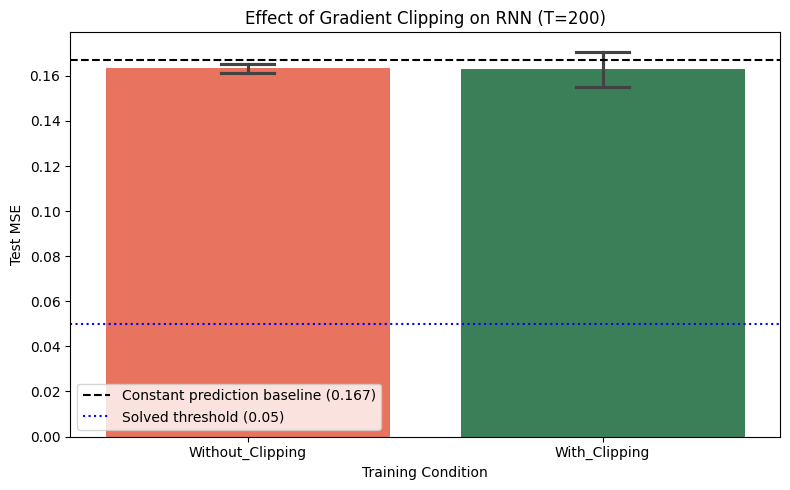

In [133]:
import seaborn as sns

plt.figure(figsize=(8, 5))

sns.barplot(
    data=ablation_df,
    x="Condition",
    y="Test MSE",
    errorbar="sd",
    capsize=0.15,
    palette=["tomato", "seagreen"]
)

plt.axhline(
    y=0.167,
    color="black",
    linestyle="--",
    label="Constant prediction baseline (0.167)"
)

plt.axhline(
    y=0.05,
    color="blue",
    linestyle=":",
    label="Solved threshold (0.05)"
)

plt.title("Effect of Gradient Clipping on RNN (T=200)")
plt.xlabel("Training Condition")
plt.ylabel("Test MSE")
plt.legend()
plt.tight_layout()
plt.show()

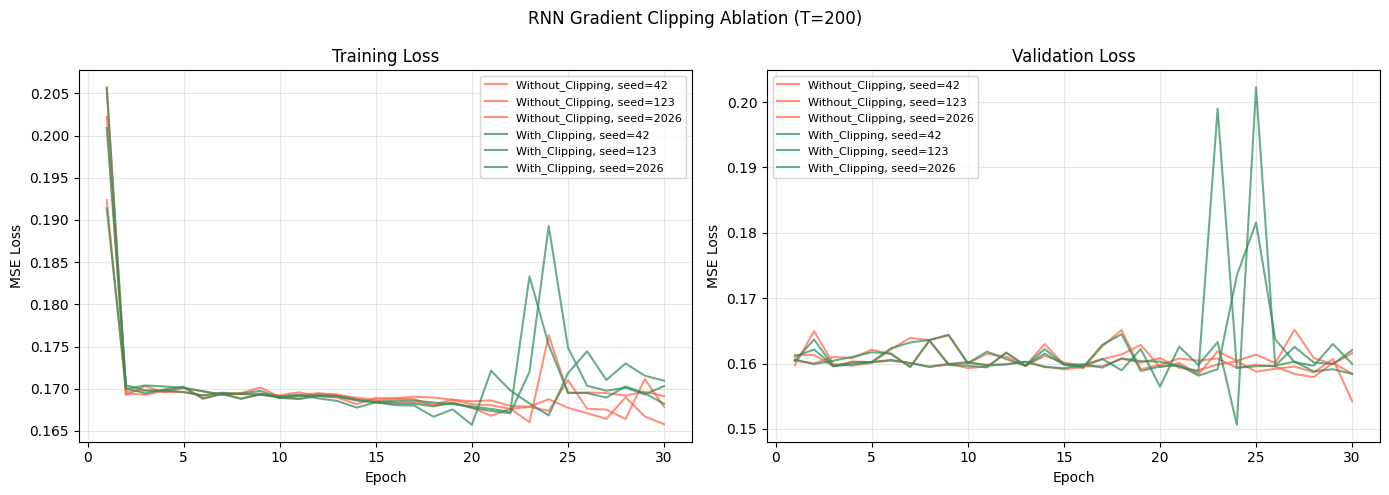

In [134]:

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

colors = {
    "Without_Clipping": "tomato",
    "With_Clipping": "seagreen"
}

for (condition, seed), result in ablation_results.items():

    history = result["history"]

    # Adjust these keys if your training function uses different names.
    train_loss = history["train_loss"]
    val_loss = history["val_loss"]

    epochs = range(1, len(train_loss) + 1)

    axes[0].plot(
        epochs,
        train_loss,
        color=colors[condition],
        alpha=0.7,
        label=f"{condition}, seed={seed}"
    )

    axes[1].plot(
        range(1, len(val_loss) + 1),
        val_loss,
        color=colors[condition],
        alpha=0.7,
        label=f"{condition}, seed={seed}"
    )

axes[0].set_title("Training Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("MSE Loss")

axes[1].set_title("Validation Loss")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("MSE Loss")

for ax in axes:
    ax.legend(fontsize=8)
    ax.grid(alpha=0.3)

plt.suptitle("RNN Gradient Clipping Ablation (T=200)")
plt.tight_layout()
plt.show()

In [135]:
ablation_df["Solved"] = ablation_df["Test MSE"] < 0.05

solved_summary = (
    ablation_df
    .groupby("Condition")["Solved"]
    .agg(["sum", "count"])
)

solved_summary.columns = ["Solved Runs", "Total Runs"]

print("Solved Experiment Counts")
display(solved_summary)

Solved Experiment Counts


,Solved Runs,Total Runs
Condition,,
With_Clipping,0,3
Without_Clipping,0,3


In [136]:
for condition in ["Without_Clipping", "With_Clipping"]:

    subset = ablation_df[
        ablation_df["Condition"] == condition
    ]

    mean_mse = subset["Test MSE"].mean()
    std_mse = subset["Test MSE"].std()

    solved = (subset["Test MSE"] < 0.05).sum()

    print(f"\n{condition}")
    print("-" * 40)
    print(f"Mean Test MSE: {mean_mse:.6f}")
    print(f"Std Test MSE:  {std_mse:.6f}")
    print(f"Solved Runs:   {solved}/3")


Without_Clipping
----------------------------------------
Mean Test MSE: 0.163367
Std Test MSE:  0.001897
Solved Runs:   0/3

With_Clipping
----------------------------------------
Mean Test MSE: 0.162826
Std Test MSE:  0.007928
Solved Runs:   0/3


In [158]:
# Create output directory
os.makedirs("results/plots", exist_ok=True)


# ==========================================
# 1. HAR RESULTS CSV
# ==========================================

# IMPORTANT: Use 'results', not the empty har_experiment_results
har_export = pd.DataFrame(results)

# Standardise column names
har_export.columns = [
    col.strip().replace(" ", "_")
    for col in har_export.columns
]

har_export.to_csv(
    "results/har_results.csv",
    index=False
)

print("HAR RESULTS SAVED")
print("Total experiments:", len(har_export))
display(har_export)


# ==========================================
# 2. ADDING PROBLEM RESULTS CSV
# ==========================================

# Use the existing DataFrame containing all 36 runs
adding_export = adding_length_df.copy()

adding_export.columns = [
    "Model",
    "Sequence_Length",
    "Seed",
    "Best_Validation_MSE",
    "Test_MSE",
    "Solved"
]

adding_export.to_csv(
    "results/adding_results.csv",
    index=False
)

print("\nADDING RESULTS SAVED")
print("Total experiments:", len(adding_export))
display(adding_export)


# ==========================================
# 3. ABLATION RESULTS CSV
# ==========================================

ablation_rows = []

for (condition, seed), result in ablation_results.items():

    ablation_rows.append({
        "Model": "RNN",
        "Condition": condition,
        "Sequence_Length": 200,
        "Seed": seed,
        "Hidden_Size": 64,
        "Gradient_Clipping": condition == "With_Clipping",
        "Max_Gradient_Norm": (
            1.0 if condition == "With_Clipping" else None
        ),
        "Test_MSE": result["test_mse"],
        "Best_Validation_Loss": result["best_val_loss"],
        "Solved": result["test_mse"] < 0.05
    })

ablation_export = pd.DataFrame(ablation_rows)

ablation_export.to_csv(
    "results/ablation_results.csv",
    index=False
)

print("\nABLATION RESULTS SAVED")
print("Total experiments:", len(ablation_export))
display(ablation_export)


# ==========================================
# 4. GENERATE SUMMARY STATISTICS
# ==========================================

print("\n========== HAR SUMMARY ==========")

har_summary = har_export.groupby("Model").agg(
    Accuracy_Mean=("Test_Accuracy", "mean"),
    Accuracy_Std=("Test_Accuracy", "std"),
    Macro_F1_Mean=("Macro_F1", "mean"),
    Macro_F1_Std=("Macro_F1", "std"),
    Parameters=("Parameters", "first"),
    Seconds_Per_Epoch=("Seconds_per_Epoch", "mean")
)

display(har_summary.round(4))


print("\n========== ADDING SUMMARY ==========")

adding_summary_export = adding_export.groupby(
    ["Model", "Sequence_Length"]
).agg(
    Mean_Test_MSE=("Test_MSE", "mean"),
    Std_Test_MSE=("Test_MSE", "std"),
    Solved_Runs=("Solved", "sum"),
    Total_Runs=("Solved", "count")
).reset_index()

display(adding_summary_export.round(6))

adding_summary_export.to_csv(
    "results/adding_summary.csv",
    index=False
)


print("\n========== ABLATION SUMMARY ==========")

ablation_summary_export = ablation_export.groupby(
    "Condition"
).agg(
    Mean_Test_MSE=("Test_MSE", "mean"),
    Std_Test_MSE=("Test_MSE", "std"),
    Solved_Runs=("Solved", "sum")
)

display(ablation_summary_export.round(6))


# ==========================================
# 5. VERIFY ALL THREE CSV FILES
# ==========================================

print("\n========== FINAL FILE VERIFICATION ==========")

for filename in [
    "har_results.csv",
    "adding_results.csv",
    "ablation_results.csv",
    "adding_summary.csv"
]:

    path = os.path.join("results", filename)

    df = pd.read_csv(path)

    print(f"{filename}: {len(df)} rows | {os.path.getsize(path)} bytes")

print("\nAll result files generated successfully!")

HAR RESULTS SAVED
Total experiments: 9


,Model,Seed,Test_Accuracy,Macro_F1,Parameters,Seconds_per_Epoch,Best_Epoch,Best_Validation_Loss
0,RNN,42,0.851035,0.847149,5190,3.954931,24,0.196119
1,RNN,123,0.857822,0.856384,5190,3.992245,29,0.228439
2,RNN,2026,0.791653,0.784125,5190,4.007188,10,0.396191
3,LSTM,42,0.917883,0.917878,19590,8.228601,16,0.099731
4,LSTM,123,0.917204,0.917983,19590,8.290926,28,0.149669
5,LSTM,2026,0.897862,0.898666,19590,8.522851,27,0.078910
6,GRU,42,0.914829,0.913242,14790,14.628330,26,0.084489
7,GRU,123,0.898202,0.896600,14790,14.558383,8,0.145625
8,GRU,2026,0.903970,0.903595,14790,15.065798,15,0.072683



ADDING RESULTS SAVED
Total experiments: 36


,Model,Sequence_Length,Seed,Best_Validation_MSE,Test_MSE,Solved
0,GRU,50,42,0.000531,0.000616,True
1,GRU,50,123,0.000664,0.000791,True
2,GRU,50,2026,0.000148,0.000168,True
3,LSTM,50,42,0.000862,0.000976,True
4,LSTM,50,123,0.000617,0.000603,True
5,LSTM,50,2026,0.000965,0.000920,True
6,RNN,50,42,0.008707,0.009904,True
7,RNN,50,123,0.004107,0.003900,True
8,RNN,50,2026,0.003167,0.003550,True
9,GRU,100,42,0.002330,0.002079,True



ABLATION RESULTS SAVED
Total experiments: 6


,Model,Condition,Sequence_Length,Seed,Hidden_Size,Gradient_Clipping,Max_Gradient_Norm,Test_MSE,Best_Validation_Loss,Solved
0,RNN,Without_Clipping,200,42,64,False,NaN,0.164564,0.158374,False
1,RNN,Without_Clipping,200,123,64,False,NaN,0.161179,0.154254,False
2,RNN,Without_Clipping,200,2026,64,False,NaN,0.164356,0.157925,False
3,RNN,With_Clipping,200,42,64,True,1.0,0.153701,0.150621,False
4,RNN,With_Clipping,200,123,64,True,1.0,0.168023,0.158423,False
5,RNN,With_Clipping,200,2026,64,True,1.0,0.166753,0.158139,False


... (3 outputs left out)

,Model,Sequence_Length,Mean_Test_MSE,Std_Test_MSE,Solved_Runs,Total_Runs
0,GRU,50,0.000525,0.000321,3,3
1,GRU,100,0.002092,0.000456,3,3
2,GRU,200,0.000392,0.000057,3,3
3,GRU,400,0.002359,0.000715,3,3
4,LSTM,50,0.000833,0.000201,3,3
5,LSTM,100,0.170128,0.000818,0,3
6,LSTM,200,0.168337,0.000202,0,3
7,LSTM,400,0.154081,0.000610,0,3
8,RNN,50,0.005785,0.003572,3,3
9,RNN,100,0.168151,0.001519,0,3



========== ABLATION SUMMARY ==========


,Mean_Test_MSE,Std_Test_MSE,Solved_Runs
Condition,,,
With_Clipping,0.162826,0.007928,0
Without_Clipping,0.163367,0.001897,0



========== FINAL FILE VERIFICATION ==========
har_results.csv: 9 rows | 932 bytes
adding_results.csv: 36 rows | 2185 bytes
ablation_results.csv: 6 rows | 626 bytes
adding_summary.csv: 12 rows | 731 bytes

All result files generated successfully!
